# Checks of the DM-electron scattering rates
Comparisons for the users interested in the validation of RAPIDD and in changing its defaults (the rates
themselves are introduced in [evaluate_ER_rates.ipynb](evaluate_ER_rates.ipynb)):
1. the four responses $R_j W_j$ and the sign of $W_2$;
2. spectra and integrated rates against Figs. 5-7 of [arXiv:1912.08204](https://arxiv.org/abs/1912.08204) (xenon and argon),
   the contact interactions at 1 GeV and the truncation of the $q$ integral at 1 MeV;
3. XENON10 limits against Figs. 8 and 10 of arXiv:1912.08204;
4. XENON1T limits against Figs. 8 and 10 of arXiv:1912.08204 and against the XENON1T S2-only data release;
5. XENONnT limits and wimprates: the differences between the RAPIDD and wimprates spectra, and the XENONnT limit
   rescaled to the RAPIDD atomic responses.

Sections 1-4 use the settings of arXiv:1912.08204: SHM with $v_0 = 220$, $v_\text{esc} = 544$,
$v_E = 244$ km/s, $\rho_\chi = 0.4$ GeV/cm$^3$, the 5 outer shells (4s, 4p, 4d, 5s, 5p).

The XENON1T response is evaluated at $E_e$ plus the energy of the de-excitation photon of the shell (63.1, 87.9,
50.3 eV for 4d, 4p, 4s, 0 for the others), the conservative signal of XENON1T and XENONnT ("electron" energy
convention, default); `rapidd.set_er_energy_convention("deposited")` uses the total deposited energy $E_e + E_b$.

$W_2$ is used by default with the sign corrected in [Liang et al., arXiv:2405.04855](https://arxiv.org/abs/2405.04855);
`rapidd.set_w2_sign("Catena")` restores the sign of arXiv:1912.08204 (only $\mathcal{O}_{7,8,12,13,14}$ depend on it).

In [1]:
import numpy as np
import rapidd
import matplotlib.pyplot as plt
import os, tempfile, warnings
import pandas as pd

In [2]:
# Halo of arXiv:1912.08204: SHM with v0 = 220 km/s, vesc = 544 km/s, v_E = 244 km/s, rho = 0.4 GeV/cm^3
halo_table = '../lib/halo_table/halo_table_SHM_1912.08204.dat'
do_calculate_halo = False  # the table is shipped with RAPIDD
if do_calculate_halo:
    rapidd.write_paper_halo(halo_table)  # = rapidd.calc_halo(halo_table, vesc=544., v0=220., ve=244., i=2)
rapidd.read_halo(halo_table)
rapidd.read_atomic_responses()  # W_1 ... W_4 of the 11 Xenon shells
# rates at 1 GeV with contact O_3, O_5, O_6, O_13-O_15 miss the q > 1 MeV part (section 2): warning silenced here
warnings.filterwarnings('ignore', category=rapidd.QMaxTruncationWarning)

rhoDM = rapidd.PAPER_HALO['rhoDM']  # GeV/cm^3
jchi = 0.5                          # DM spin
shells = rapidd.XE_SHELLS_PAPER     # 4s, 4p, 4d, 5s, 5p (None: all the 11 shells, as in MadDM)
YR = 365.25                         # days per year

## 1. Contributions of the responses $R_j W_j$ and sign of $W_2$
The four terms $R_j W_j$ (Fig. 7 of the paper): `resp=j` keeps only $R_j W_j$. The contributions can be negative ($\dagger$, plotted as absolute value), e.g. $R_4 W_4$ for $\mathcal{O}_{15}$.

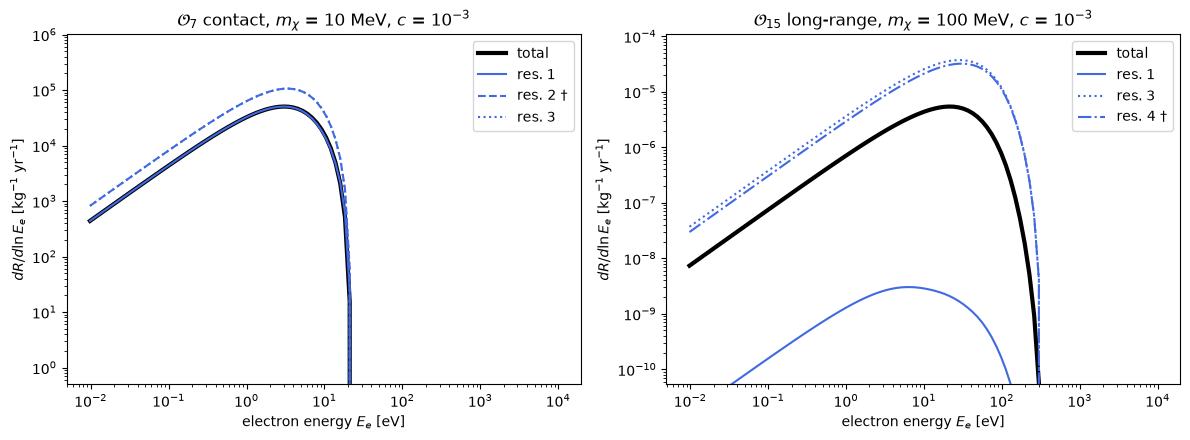

In [3]:
cases = [(7, 'contact', 0.01), (15, 'long-range', 0.1)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (i, inter, m_chi) in zip(axes, cases):
    rapidd.reset_coefficients()
    rapidd.set_any_Ecoeff(1e-3, i, interaction=inter)
    tot = rapidd.difrate_electron(rhoDM, m_chi, jchi, shells=shells)
    ax.plot(tot['E'] * 1e3, tot['dRdlnE'] * YR, 'k', lw=3, label='total')
    for j, ls in zip((1, 2, 3, 4), ['-', '--', ':', '-.']):
        r = rapidd.difrate_electron(rhoDM, m_chi, jchi, shells=shells, resp=j)
        if np.all(r['dRdlnE'] == 0):
            continue
        neg = r['dRdlnE'].min() < 0
        ax.plot(r['E'] * 1e3, np.abs(r['dRdlnE']) * YR, ls=ls, color='royalblue',
                label=f'res. {j}' + (r' $\dagger$' if neg else ''))
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(np.max(tot['dRdlnE'] * YR) * 1e-5, np.max(tot['dRdlnE'] * YR) * 20)
    ax.set_xlabel('electron energy $E_e$ [eV]')
    ax.set_ylabel(r'$dR/d\ln E_e$ [kg$^{-1}$ yr$^{-1}$]')
    ax.set_title(rf'$\mathcal{{O}}_{{{i}}}$ {inter}, $m_\chi$ = {m_chi*1e3:g} MeV, $c$ = $10^{{-3}}$')
    ax.legend()
plt.tight_layout()
plt.show()

### Sign of $W_2$
With the sign of arXiv:2405.04855 (default) $R_2 W_2$ is negative for $\mathcal{O}_7$ and nearly cancels $R_3 W_3$, so the rate is close to $R_1 W_1$ alone; with the sign of arXiv:1912.08204 the two terms add up.

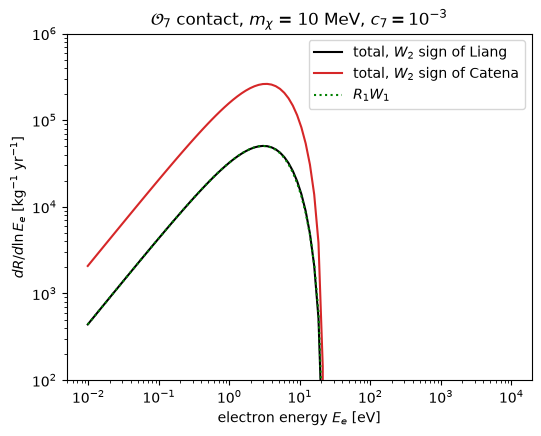

In [4]:
rapidd.reset_coefficients()
rapidd.set_any_Ecoeff(1e-3, 7)
fig, ax = plt.subplots(figsize=(6, 4.5))
for convention, color in (('Liang', 'k'), ('Catena', 'tab:red')):
    rapidd.set_w2_sign(convention)
    r = rapidd.difrate_electron(rhoDM, 0.01, jchi, shells=shells)
    ax.plot(r['E'] * 1e3, r['dRdlnE'] * YR, color=color, label=f'total, $W_2$ sign of {convention}')
rapidd.set_w2_sign('Liang')
r1 = rapidd.difrate_electron(rhoDM, 0.01, jchi, shells=shells, resp=1)
ax.plot(r1['E'] * 1e3, r1['dRdlnE'] * YR, 'g:', label='$R_1 W_1$')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e2, 1e6)
ax.set_xlabel('electron energy $E_e$ [eV]')
ax.set_ylabel(r'$dR/d\ln E_e$ [kg$^{-1}$ yr$^{-1}$]')
ax.set_title(r'$\mathcal{O}_7$ contact, $m_\chi$ = 10 MeV, $c_7 = 10^{-3}$')
ax.legend()
plt.show()

## 2. Spectra and integrated rates: Figs. 5-7 of arXiv:1912.08204
Paper / RAPIDD for the spectra of Figs. 5 and 7 and the xenon bars of Fig. 6 (extracted with
`tests/data/extract_paper_figures.py`), with the settings and the sign of $W_2$ of the paper.
Figs. 5-7 are computed with $\rho_\chi = 0.3$ GeV/cm$^3$, not with the 0.4 stated in the paper (without correction they
are 0.752 times RAPIDD for all the operators, masses and responses, see below): the values of the paper are multiplied
by `rho_fix` = 0.4/0.3, as in `tests/test_electron_paper.py`.

The paper computed its atomic responses with DarkARC (Python, v1.0 of 2019, no longer maintained: $q \in [1, 1000]$ keV
on a 100 x 100 grid, $\ell' \le 7$, radial integrals with tolerances $10^{-3}$/$10^{-2}$). The RAPIDD tables come from
DarkART 594ffb5 (C++, the maintained successor of DarkARC), converged in the radial grid (5000 vs 10000 points:
identical) and in $\ell'$ ($\ell' \le 40$ fixed: $W_j$ within 0.5%, $(q/m_e)^2 W_3 - W_4$ within 0.25%): where the
two differ, the DarkART/RAPIDD results are the more reliable.

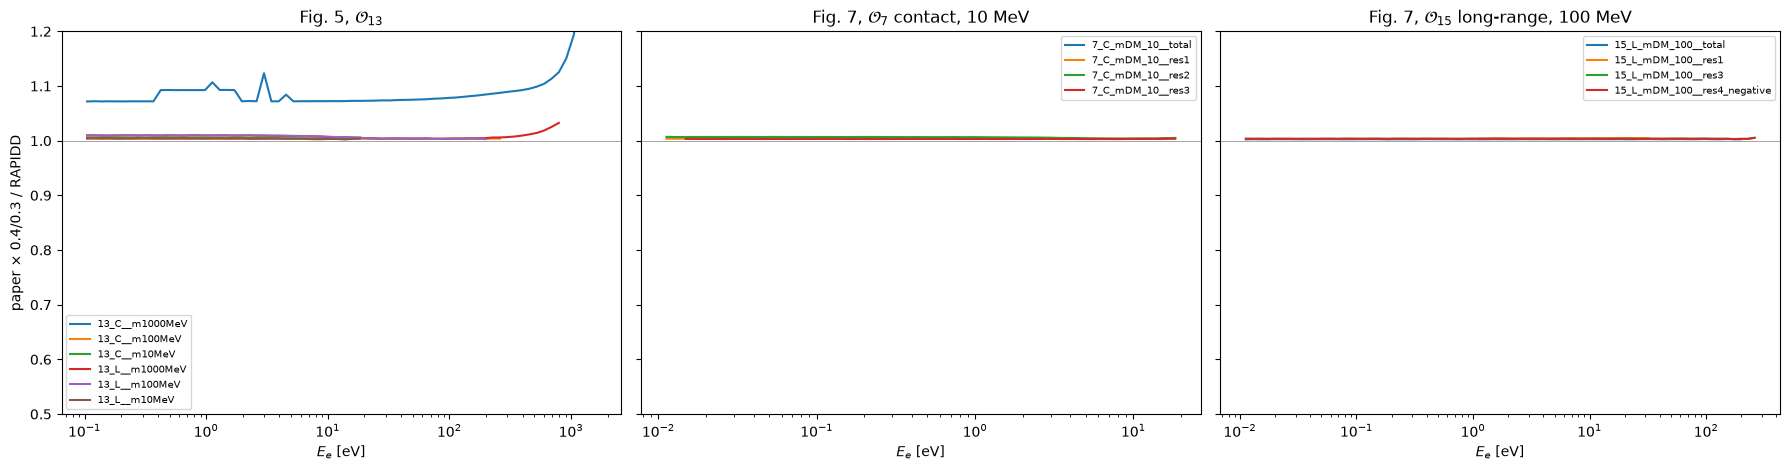

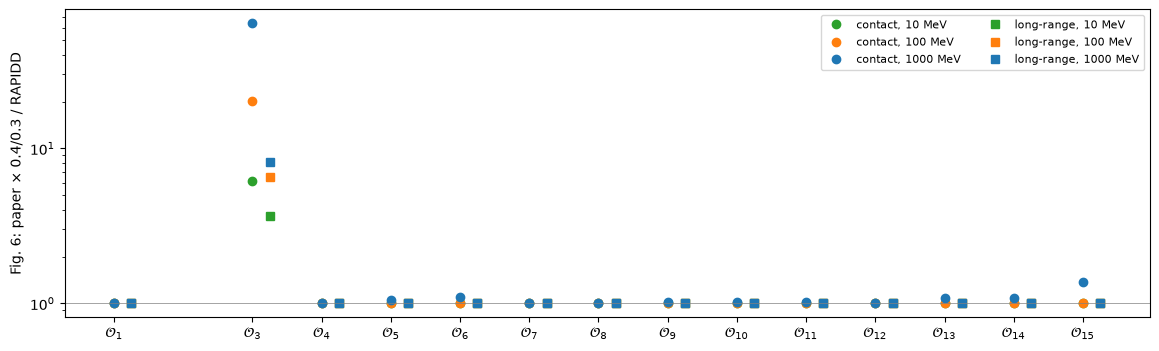

Fig. 6, O_3 contact, 10 MeV: paper x 0.4/0.3 / RAPIDD = 6.201
Fig. 6, O_3 contact, 100 MeV: paper x 0.4/0.3 / RAPIDD = 20.363
Fig. 6, O_3 contact, 1000 MeV: paper x 0.4/0.3 / RAPIDD = 64.019
Fig. 6, O_5 contact, 1000 MeV: paper x 0.4/0.3 / RAPIDD = 1.059
Fig. 6, O_6 contact, 1000 MeV: paper x 0.4/0.3 / RAPIDD = 1.095
Fig. 6, O_13 contact, 1000 MeV: paper x 0.4/0.3 / RAPIDD = 1.082
Fig. 6, O_14 contact, 1000 MeV: paper x 0.4/0.3 / RAPIDD = 1.082
Fig. 6, O_15 contact, 1000 MeV: paper x 0.4/0.3 / RAPIDD = 1.380
Fig. 6, O_3 long-range, 10 MeV: paper x 0.4/0.3 / RAPIDD = 3.640
Fig. 6, O_3 long-range, 100 MeV: paper x 0.4/0.3 / RAPIDD = 6.512
Fig. 6, O_3 long-range, 1000 MeV: paper x 0.4/0.3 / RAPIDD = 8.170


In [5]:
paper = '../tests/data/paper_1912.08204/'
rho_fix = 0.4 / 0.3  # Figs. 5-7 of the paper use rho = 0.3 GeV/cm^3
rapidd.set_w2_sign('Catena')
C13, L13, C7, L15 = {(13, 'contact'): 1e-3}, {(13, 'long-range'): 1e-3}, {(7, 'contact'): 1e-3}, {(15, 'long-range'): 1e-3}
figs = [(f'Xe_coup_13_C__m{lab}', m, C13, None) for lab, m in (('1000MeV', 1.), ('100MeV', .1), ('10MeV', .01))] \
    + [(f'Xe_coup_13_L__m{lab}', m, L13, None) for lab, m in (('1000MeV', 1.), ('100MeV', .1), ('10MeV', .01))] \
    + [(f'Xe_coup_7_C_mDM_10__{lab}', .01, C7, resp) for lab, resp in (('total', None), ('res1', 1), ('res2', 2), ('res3', 3))] \
    + [(f'Xe_coup_15_L_mDM_100__{lab}', .1, L15, resp) for lab, resp in (('total', None), ('res1', 1), ('res3', 3), ('res4_negative', 4))]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for name, m, coeffs, resp in figs:
    rapidd.reset_coefficients()
    for (op, inter), val in coeffs.items():
        rapidd.set_any_Ecoeff(val, op, interaction=inter)
    r = rapidd.difrate_electron(rhoDM, m, jchi, shells=shells, resp=resp)
    x, y_paper = np.loadtxt(f'{paper}{name}.csv', delimiter=',').T
    y_paper = y_paper * rho_fix
    ok = r['dRdlnE'] != 0
    y = np.exp(np.interp(np.log(x), np.log(r['E'][ok] * 1e3), np.log(np.abs(r['dRdlnE'][ok]) * YR)))
    sel = y_paper > 1e-3 * y_paper.max()
    ax = axes[0] if 'coup_13' in name else axes[1] if 'coup_7' in name else axes[2]
    ax.plot(x[sel], y_paper[sel] / y[sel], label=name.replace('Xe_coup_', ''))
for ax, title in zip(axes, ('Fig. 5, $\\mathcal{O}_{13}$', 'Fig. 7, $\\mathcal{O}_7$ contact, 10 MeV',
                            'Fig. 7, $\\mathcal{O}_{15}$ long-range, 100 MeV')):
    ax.axhline(1, color='grey', lw=0.5)
    ax.set_ylim(0.5, 1.2)
    ax.set_xscale('log')
    ax.set_xlabel('$E_e$ [eV]')
    ax.set_title(title)
    ax.legend(fontsize=7)
axes[0].set_ylabel(r'paper $\times$ 0.4/0.3 / RAPIDD')
plt.tight_layout()
plt.show()

rows = np.genfromtxt(f'{paper}Total_Rate_Comparison.csv', delimiter=',', dtype=None, encoding=None, comments='#')
fig6 = {}
for inter, op, target, m, val in rows:
    if target != 'Xe':
        continue
    rapidd.reset_coefficients()
    rapidd.set_any_Ecoeff(1., int(op), interaction=str(inter))
    fig6[str(inter), int(op), float(m)] = rho_fix * float(val) / (rapidd.total_rate_electron(rhoDM, float(m) / 1e3, jchi, shells=shells) * YR)
fig, ax = plt.subplots(figsize=(14, 4))
for k, (inter, mk) in enumerate((('contact', 'o'), ('long-range', 's'))):
    for m, color in ((10., 'tab:green'), (100., 'tab:orange'), (1000., 'tab:blue')):
        ops = [op for (i, op, mm) in fig6 if i == inter and mm == m]
        ax.plot(np.array(ops) + 0.25 * k, [fig6[inter, op, m] for op in ops], mk, color=color,
                label=f'{inter}, {m:g} MeV')
ax.axhline(1, color='grey', lw=0.5)
ax.set_yscale('log')
ax.set_xticks(rapidd.ELECTRON_OPERATORS)
ax.set_xticklabels([f'$\\mathcal{{O}}_{{{i}}}$' for i in rapidd.ELECTRON_OPERATORS])
ax.set_ylabel(r'Fig. 6: paper $\times$ 0.4/0.3 / RAPIDD')
ax.legend(ncol=2, fontsize=8)
plt.show()
for (inter, op, m), v in sorted(fig6.items(), key=lambda t: (t[0][0], t[0][2], t[0][1])):
    if abs(v - 1) > 0.02:
        print(f'Fig. 6, O_{op} {inter}, {m:g} MeV: paper x 0.4/0.3 / RAPIDD = {v:.3f}')
rapidd.set_w2_sign('Liang')
rapidd.reset_coefficients()

Results:
- Figs. 5-7 use $\rho_\chi = 0.3$ GeV/cm$^3$: without the factor 0.4/0.3 the paper is **0.752** times RAPIDD for all the operators, masses and responses, flat in $E_e$, while its Figs. 8-10 ($\rho_\chi = 0.4$) agree with RAPIDD (within 4% for the XENON10 limits, section 3, and 1% in median for the model spectra of Fig. 9, `test_model_spectra_fig_9`). arXiv:2405.04855 also finds Fig. 7 to be ~3/4 of the formula. With the factor 0.4/0.3 spectra and bars agree within 2% (0.5% for most of them), except for the cases below.
- Contact interactions at 1 GeV: the $\mathcal{O}_5$, $\mathcal{O}_6$, $\mathcal{O}_{13}$, $\mathcal{O}_{14}$ bars (and $\mathcal{O}_3$ with $+c_3^2/4$, see below) of the paper are 6-9% higher than RAPIDD with the 5 outer shells, and $\mathcal{O}_{15}$ 38% higher (the other bars at 1 GeV agree within 1.5%); the spectrum of $\mathcal{O}_{13}$ contact at 1 GeV (Fig. 5) is 7% higher, up to 1.7 times at the end point. These rates come from large $q$ (the integrand is still large at $q = 1$ MeV) and are explained below: the paper also includes the shells 3s, 3p, 3d and integrates effectively up to $q \simeq 1.05$ MeV; only $\mathcal{O}_5$ (+2%) and $\mathcal{O}_{15}$ (+11%) keep a residual, from the cancellation between $R_3 W_3$ and $R_4 W_4$.
- **Mismatch of the $\mathcal{O}_3$ bars of Fig. 6** (the points at 3-60 in the plot above): for $j_\chi = 1/2$ the DM responses of the paper give exactly the same rate for $\mathcal{O}_3$ and $\mathcal{O}_5$ (`tests/test_electron_paper.py::test_O3_equals_O5`; the same holds for the DM responses $a_1$, $a_2$ of arXiv:2405.04855), while the paper's $\mathcal{O}_3$ bars are 3-60 times its $\mathcal{O}_5$ bars. The rate of these operators is $\propto \frac{c^2}{4}\left(\frac{q^2}{m_e^2} W_3 - W_4\right) = \frac{c^2}{4}\sum \left|\frac{\mathbf{q}}{m_e}\times\mathbf{f}_{1\to2}\right|^2 \ge 0$, a strong cancellation ($R_3 W_3$ is 2-77 times the total). The paper's $\mathcal{O}_3$ bars are reproduced, as all the other bars, with the opposite sign of $R_4 W_4$, i.e. with $+c_3^2/4$ in $R_4$ (`test_total_rate_O3_fig_6_opposite_R4_sign`; the same holds for the argon bars, with the DarkART tables of argon: paper $\mathcal{O}_3/\mathcal{O}_5$ reproduced within 0.2%). RAPIDD keeps the sign of Eq. (DM response 4) of the paper, which gives the positive sum of $|\mathbf{q}\times\mathbf{f}|^2$ above: the figure, not the equation, has the wrong sign.

Before the regeneration of the Xe 4d atomic responses (`lib/atomic_responses/README.md`: the old tables had been produced with the binding energy of 5p in the continuum states) the paper looked higher than RAPIDD by up to 1.3 at large $q$ (contact interactions at 100 MeV - 1 GeV), and up to 1.7 for $\mathcal{O}_5$, $\mathcal{O}_{15}$, where the cancellation amplifies the error on $W_3$, $W_4$. The left sum on the $q$ grid (now Simpson's rule in $\ln q$) also overestimated all the rates by 1.8%.

### Contact interactions at 1 GeV: inner shells and $q$ range
The text of the paper says that the 5 outer shells (4s, 4p, 4d, 5s, 5p) are summed, but its contact bars at 1 GeV are
reproduced only if the shells 3s, 3p, 3d are also included: they contribute at large $q$ and matter only for the operators
whose rate grows with $q$. Below RAPIDD / (paper $\times$ 0.4/0.3) for the bars of Fig. 6 at 1 GeV (contact) and for the
$\mathcal{O}_{13}$ spectrum of Fig. 5, with 5 and 8 shells ($q \le 1$ MeV, the RAPIDD default).

Fig. 6, contact, 1 GeV: RAPIDD / (paper x 0.4/0.3), q <= 1 MeV


,5 shells,8 shells,8 / 5 shells
O_1,0.996,0.997,1.000
O_3 (+c_3^2/4),0.931,0.972,1.044
O_4,0.997,0.997,1.000
O_5,0.944,0.976,1.033
O_6,0.913,0.969,1.062
O_7,0.988,0.995,1.007
O_8,0.988,0.995,1.007
O_9,0.986,0.994,1.009
O_10,0.986,0.994,1.009
O_11,0.986,0.994,1.009


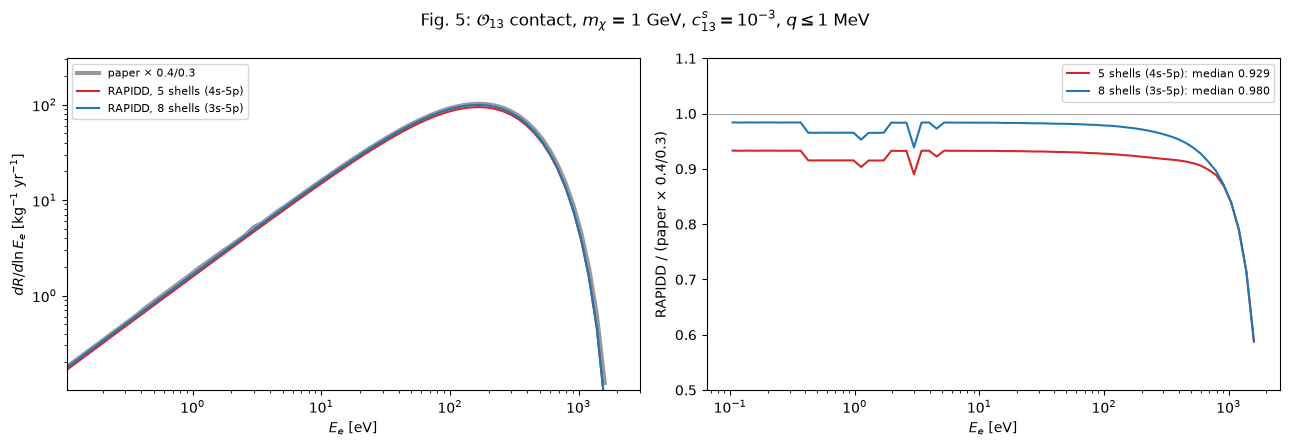

In [6]:
rapidd.set_w2_sign('Catena')
shells8 = rapidd.XE_SHELLS_PAPER + ('3s', '3p', '3d')
bars_1gev = {int(op): rho_fix * float(val) for inter, op, target, m, val in rows
             if target == 'Xe' and str(inter) == 'contact' and float(m) == 1000.}
table = {}
for op in rapidd.ELECTRON_OPERATORS:
    rapidd.reset_coefficients()
    rapidd.set_any_Ecoeff(1., op)
    for sh, lab in ((shells, '5 shells'), (shells8, '8 shells')):
        r = rapidd.total_rate_electron(rhoDM, 1., jchi, shells=sh) * YR
        table.setdefault(f'O_{op}', {})[lab] = r / bars_1gev[op]
        if op == 3:  # bars of the paper: opposite sign of R_4 W_4 (see below)
            r4 = rapidd.total_rate_electron(rhoDM, 1., jchi, shells=sh, resp=4) * YR
            table.setdefault('O_3 (+c_3^2/4)', {})[lab] = (r - 2 * r4) / bars_1gev[op]
tab = pd.DataFrame(table).T
tab['8 / 5 shells'] = tab['8 shells'] / tab['5 shells']
print('Fig. 6, contact, 1 GeV: RAPIDD / (paper x 0.4/0.3), q <= 1 MeV')
display(tab.drop('O_3').round(3))

rapidd.reset_coefficients()
rapidd.set_any_Ecoeff(1e-3, 13)
x, y_paper = np.loadtxt(f'{paper}Xe_coup_13_C__m1000MeV.csv', delimiter=',').T
y_paper = y_paper * rho_fix
sel = y_paper > 1e-3 * y_paper.max()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(x[sel], y_paper[sel], 'k', lw=3, alpha=0.4, label=r'paper $\times$ 0.4/0.3')
for sh, lab, color in ((shells, '5 shells (4s-5p)', 'tab:red'), (shells8, '8 shells (3s-5p)', 'tab:blue')):
    r = rapidd.difrate_electron(rhoDM, 1., jchi, shells=sh)
    ok = r['dRdlnE'] > 0
    y = np.exp(np.interp(np.log(x), np.log(r['E'][ok] * 1e3), np.log(r['dRdlnE'][ok] * YR)))
    axes[0].loglog(r['E'][ok] * 1e3, r['dRdlnE'][ok] * YR, color=color, label=f'RAPIDD, {lab}')
    axes[1].plot(x[sel], y[sel] / y_paper[sel], color=color,
                 label=f'{lab}: median {np.median(y[sel] / y_paper[sel]):.3f}')
axes[0].set_xlim(x[sel].min(), 3e3)
axes[0].set_ylim(y_paper[sel].max() * 1e-3, y_paper[sel].max() * 3)
axes[0].set_ylabel(r'$dR/d\ln E_e$ [kg$^{-1}$ yr$^{-1}$]')
axes[1].axhline(1, color='grey', lw=0.5)
axes[1].set_xscale('log')
axes[1].set_ylim(0.5, 1.1)
axes[1].set_ylabel(r'RAPIDD / (paper $\times$ 0.4/0.3)')
for ax in axes:
    ax.set_xlabel('$E_e$ [eV]')
    ax.legend(fontsize=8)
fig.suptitle(r'Fig. 5: $\mathcal{O}_{13}$ contact, $m_\chi$ = 1 GeV, $c_{13}^s = 10^{-3}$, $q \leq 1$ MeV')
plt.tight_layout()
plt.show()
rapidd.set_w2_sign('Liang')
rapidd.reset_coefficients()

- With the 8 shells the contact bars at 1 GeV become RAPIDD/paper = 0.970 ($\mathcal{O}_6$), 0.971 ($\mathcal{O}_{13}$, $\mathcal{O}_{14}$), 0.972 ($\mathcal{O}_3$ with $+c_3^2/4$), 0.976 ($\mathcal{O}_5$), 0.865 ($\mathcal{O}_{15}$), while $\mathcal{O}_1$, $\mathcal{O}_4$, $\mathcal{O}_7$-$\mathcal{O}_{12}$ change by less than 1% (`tests/test_electron_paper.py::test_1gev_contact_explained_by_inner_shells`); the median of the $\mathcal{O}_{13}$ spectrum goes from 0.928 to 0.980.
- The rest of the gap comes from the end of the $q$ integral. With DarkART tables extended beyond 1 MeV (generated outside the repository and not shipped; the numbers below are quoted, not recomputed here: see `lib/atomic_responses/README.md` to reproduce them), the paper is reproduced with an effective $q_\text{max} \simeq 1.05$ MeV (DarkARC integrates on its own $q$ grid up to 1 MeV, plus interpolation/extrapolation at the edge): with 8 shells and $q \le 1.045$-$1.05$ MeV the bars of $\mathcal{O}_6$, $\mathcal{O}_{13}$/$\mathcal{O}_{14}$, $\mathcal{O}_3$ (with $+c_3^2/4$) and the $\mathcal{O}_{13}$ spectrum up to 1 keV agree within 0.3% (spectrum median 0.996-0.997), and the long-range bars at 1 GeV within 0.6%. Integrating instead up to the kinematic end point (5.3 MeV) would put RAPIDD up to 200 times above the paper.
- $\mathcal{O}_5$ (+2%) and $\mathcal{O}_{15}$ (+11%) keep a residual: their rate is the difference $R_3 W_3 - R_4 W_4$ (the transverse part $\frac{q^2}{m_e^2} W_3 - W_4$), with terms up to ~400 times the result in xenon (~1100 for the argon 2s shell at 1 MeV). This is most likely a numerical inaccuracy of DarkARC (adaptive radial integrals with relative tolerances $10^{-3}$-$10^{-2}$, $\ell' \le 7$): DarkART is converged on this difference within 0.25%. For argon (below) the effect is much larger.
- Excluded as causes: linear or nearest-node interpolation of the tables, the halo, the truncation $\ell' \le 7$ of DarkARC (which however explains the 0.4% of the long-range $\mathcal{O}_7$, $\mathcal{O}_8$, $\mathcal{O}_{12}$, $\mathcal{O}_{13}$, $\mathcal{O}_{14}$ bars), the number of $q$ points (DarkART tables with 399 $q$ points change these rates by < 0.04%).

**Conclusion**: the 1 GeV discrepancies come from the paper's computation (inner shells included, effective $q_\text{max} \simeq 1.05$ MeV, inaccurate cancellation for $\mathcal{O}_5$, $\mathcal{O}_{15}$); where DarkARC and DarkART differ, the DarkART tables used by RAPIDD are the more reliable.

### Truncation at $q_\text{max} = 1$ MeV
RAPIDD keeps $q_\text{max} = 1\,\text{MeV} \simeq 2 m_e$ (the end of the tables, as DarkARC, DarkART and obscura): above it the NREFT and the non-relativistic wave functions are not valid. The operators whose rate grows with $q$ lose part of their rate for heavy DM; fraction of the contact rate with $q \le 1$ MeV (8 shells, DarkART tables extended up to 5.29 MeV; `rapidd.QMAX_LOST_FRACTION`):

| $m_\chi$ [GeV] | $\mathcal{O}_3$, $\mathcal{O}_5$ | $\mathcal{O}_6$ | $\mathcal{O}_{13}$, $\mathcal{O}_{14}$ | $\mathcal{O}_{15}$ |
|:--|:--|:--|:--|:--|
| 0.3 | 99.99% | 99.8% | 99.8% | 99.8% |
| 0.5 | 99.6% | 96% | 96% | 95% |
| 0.7 | 98.5% | 87% | 88% | 81% |
| 1 | 96% | 73% | 75% | 62% |

$\mathcal{O}_1$ and $\mathcal{O}_4$ (MadDM) keep more than 99.98% at 1 GeV, as do the long-range couplings. For $m_\chi > 0.3$ GeV and a contact coefficient of $\mathcal{O}_3$, $\mathcal{O}_5$, $\mathcal{O}_6$, $\mathcal{O}_{13}$, $\mathcal{O}_{14}$ or $\mathcal{O}_{15}$, `difrate_electron` issues a `rapidd.QMaxTruncationWarning` with the lost fraction (once per combination of target, operators and mass range; silenced in this notebook).

### Argon
`rapidd.read_atomic_responses(target='Ar')` reads the argon tables (DarkART 594ffb5, all the 5 occupied shells 1s, 2s, 2p, 3s, 3p as in the paper, same grid as xenon); `target='Ar'` in `difrate_electron` / `total_rate_electron`. Below RAPIDD / (paper $\times$ 0.4/0.3) for the argon bars of Fig. 6 and the argon spectra of Figs. 5 ($\mathcal{O}_6$) and 7.

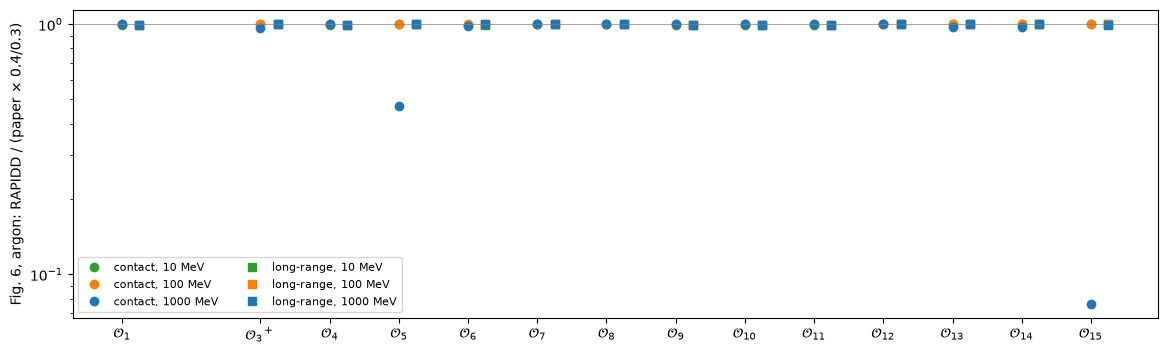

Fig. 6 argon, O_3+ contact, 1000 MeV: RAPIDD / (paper x 0.4/0.3) = 0.964
Fig. 6 argon, O_5 contact, 1000 MeV: RAPIDD / (paper x 0.4/0.3) = 0.472
Fig. 6 argon, O_6 contact, 1000 MeV: RAPIDD / (paper x 0.4/0.3) = 0.982
Fig. 6 argon, O_13 contact, 1000 MeV: RAPIDD / (paper x 0.4/0.3) = 0.973
Fig. 6 argon, O_14 contact, 1000 MeV: RAPIDD / (paper x 0.4/0.3) = 0.973
Fig. 6 argon, O_15 contact, 1000 MeV: RAPIDD / (paper x 0.4/0.3) = 0.076
Fig. 6 argon, O_15 long-range, 1000 MeV: RAPIDD / (paper x 0.4/0.3) = 0.990


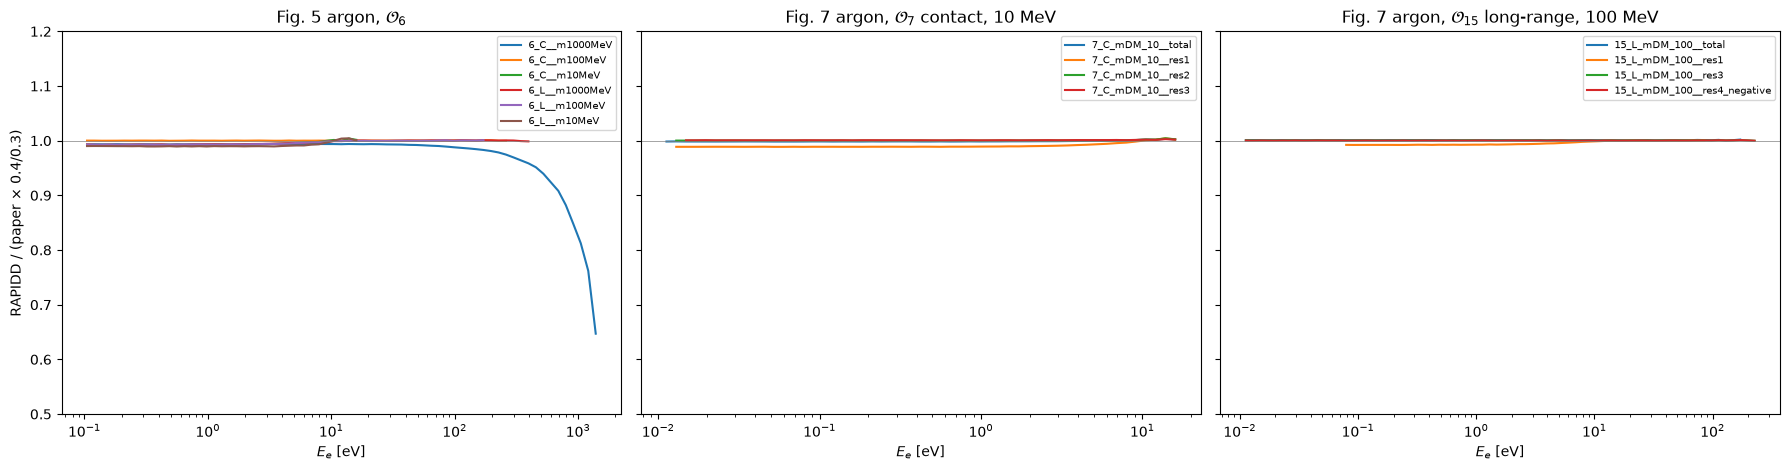

In [7]:
rapidd.set_w2_sign('Catena')
rapidd.read_atomic_responses(target='Ar')
fig6_ar = {}
for inter, op, target, m, val in rows:
    if target != 'Ar':
        continue
    inter, op, m = str(inter), int(op), float(m)
    rapidd.reset_coefficients()
    rapidd.set_any_Ecoeff(1., op, interaction=inter)
    r = rapidd.total_rate_electron(rhoDM, m / 1e3, jchi, target='Ar') * YR
    if op == 3:  # opposite sign of R_4 W_4, as for xenon
        r -= 2 * rapidd.total_rate_electron(rhoDM, m / 1e3, jchi, target='Ar', resp=4) * YR
    fig6_ar[inter, op, m] = r / (rho_fix * float(val))
fig, ax = plt.subplots(figsize=(14, 4))
for k, (inter, mk) in enumerate((('contact', 'o'), ('long-range', 's'))):
    for m, color in ((10., 'tab:green'), (100., 'tab:orange'), (1000., 'tab:blue')):
        ops = [op for (i, op, mm) in fig6_ar if i == inter and mm == m]
        ax.plot(np.array(ops) + 0.25 * k, [fig6_ar[inter, op, m] for op in ops], mk, color=color,
                label=f'{inter}, {m:g} MeV')
ax.axhline(1, color='grey', lw=0.5)
ax.set_yscale('log')
ax.set_xticks(rapidd.ELECTRON_OPERATORS)
ax.set_xticklabels([f'$\\mathcal{{O}}_{{{i}}}$' + ('$^+$' if i == 3 else '') for i in rapidd.ELECTRON_OPERATORS])
ax.set_ylabel(r'Fig. 6, argon: RAPIDD / (paper $\times$ 0.4/0.3)')
ax.legend(ncol=2, fontsize=8)
plt.show()
for (inter, op, m), v in sorted(fig6_ar.items(), key=lambda t: (t[0][0], t[0][2], t[0][1])):
    if abs(v - 1) > 0.01:
        print(f'Fig. 6 argon, O_{op}{"+" if op == 3 else ""} {inter}, {m:g} MeV: RAPIDD / (paper x 0.4/0.3) = {v:.3f}')

C6, L6 = {(6, 'contact'): 1e-3}, {(6, 'long-range'): 1e-3}
figs_ar = [(f'Ar_coup_6_C__m{lab}', m, C6, None) for lab, m in (('1000MeV', 1.), ('100MeV', .1), ('10MeV', .01))] \
    + [(f'Ar_coup_6_L__m{lab}', m, L6, None) for lab, m in (('1000MeV', 1.), ('100MeV', .1), ('10MeV', .01))] \
    + [(f'Ar_coup_7_C_mDM_10__{lab}', .01, C7, resp) for lab, resp in (('total', None), ('res1', 1), ('res2', 2), ('res3', 3))] \
    + [(f'Ar_coup_15_L_mDM_100__{lab}', .1, L15, resp) for lab, resp in (('total', None), ('res1', 1), ('res3', 3), ('res4_negative', 4))]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for name, m, coeffs, resp in figs_ar:
    rapidd.reset_coefficients()
    for (op, inter), val in coeffs.items():
        rapidd.set_any_Ecoeff(val, op, interaction=inter)
    r = rapidd.difrate_electron(rhoDM, m, jchi, resp=resp, target='Ar')
    x, y_paper = np.loadtxt(f'{paper}{name}.csv', delimiter=',').T
    y_paper = y_paper * rho_fix
    ok = r['dRdlnE'] != 0
    y = np.exp(np.interp(np.log(x), np.log(r['E'][ok] * 1e3), np.log(np.abs(r['dRdlnE'][ok]) * YR)))
    sel = y_paper > 1e-3 * y_paper.max()
    ax = axes[0] if 'coup_6' in name else axes[1] if 'coup_7' in name else axes[2]
    ax.plot(x[sel], y[sel] / y_paper[sel], label=name.replace('Ar_coup_', ''))
for ax, title in zip(axes, ('Fig. 5 argon, $\\mathcal{O}_6$', 'Fig. 7 argon, $\\mathcal{O}_7$ contact, 10 MeV',
                            'Fig. 7 argon, $\\mathcal{O}_{15}$ long-range, 100 MeV')):
    ax.axhline(1, color='grey', lw=0.5)
    ax.set_ylim(0.5, 1.2)
    ax.set_xscale('log')
    ax.set_xlabel('$E_e$ [eV]')
    ax.set_title(title)
    ax.legend(fontsize=7)
axes[0].set_ylabel(r'RAPIDD / (paper $\times$ 0.4/0.3)')
plt.tight_layout()
plt.show()
rapidd.set_w2_sign('Liang')
rapidd.reset_coefficients()

Results for argon:
- At 10 and 100 MeV and for all the long-range couplings the argon bars of Fig. 6 and the spectra of Figs. 5 and 7 agree within 1% (`tests/test_electron_paper.py::test_*_argon`), as for xenon after the factor 0.4/0.3: the argon tables of RAPIDD are validated.
- Contact at 1 GeV: RAPIDD/paper = 0.982 ($\mathcal{O}_6$), 0.973 ($\mathcal{O}_{13}$, $\mathcal{O}_{14}$), 0.964 ($\mathcal{O}_3$ with $+c_3^2/4$): the end of the $q$ integral, as for xenon (with $q_\text{max} = 1.045$ MeV, from extended DarkART tables not shipped and not recomputed here: 1.000, 0.991, 0.981); the $\mathcal{O}_6$ spectrum at 1 GeV has median 0.993 and drops to 0.65 at the end point.
- The paper's $\mathcal{O}_5$ and $\mathcal{O}_{15}$ at 1 GeV are 2.1 and 13 times RAPIDD (RAPIDD/paper = 0.472, 0.076), independently of $q_\text{max}$: the cancellation between $R_3 W_3$ and $R_4 W_4$ is even stronger in argon (the terms are up to ~1100 times their difference for 2s at $q$ = 1 MeV), and the paper's (DarkARC) bars are dominated by its numerical error. RAPIDD (DarkART, $\ell'$ converged, transverse part within 0.25%) is the reference.

## 3. XENON10 limits: Figs. 8 and 10 of arXiv:1912.08204
`rapidd.electron_limits_vs_mass` uses the scaling rate $\propto$ coupling$^2$: XENON10 with a Poisson limit in each bin independently (the strongest bin is kept, as in the paper), XENON1T with a Poisson limit in the ROI after subtracting the expected background.

RAPIDD / paper at all the points extracted from Figs. 8 and 10 (`tests/data/paper_1912.08204`, 4-850 MeV), with the halo, $\rho_\chi$ and shells of the paper:

| coupling | $W_2$ sign of the paper (Catena) | $W_2$ sign of arXiv:2405.04855 (Liang, default) |
|:--|:--|:--|
| $c_1^s$ | 1.00-1.04 (median 1.02) | same (no $W_2$) |
| $c_8^s$ | 0.99-1.04 (median 1.02) | 2.0-3.2 (median 2.9) |
| $c_{13}^s$ | 0.99-1.04 (median 1.01) | 2.3-3.8 (median 3.2) |
| $c_1^\ell$ | 1.04 | same (no $W_2$) |
| $c_8^\ell$ | 1.03-1.04 | 1.9-2.1 (median 2.05) |
| $c_{13}^\ell$ | 1.00-1.04 (median 1.02) | 1.9-2.8 (median 2.7) |
| anapole | 0.99-1.04 (median 1.01) | 1.4-1.8 (median 1.8) |
| magnetic dipole | 1.00-1.04 (median 1.02) | same (no $W_2$) |
| electric dipole | 1.03-1.04 | same (no $W_2$) |

So with the sign of the paper the agreement is within 4% at all masses, for all the couplings: within 1% for the contact couplings above 100 MeV, while below 20 MeV and for the long-range couplings, where the lowest S2 bin dominates, RAPIDD is 3.7% weaker. The XENON10 response integrates $dR/dE_e$ (interpolated as a power law between the grid points) over $E_e$ in each bin of the number of primary quanta $n_1 = \lfloor E_e/W \rfloor$. The legacy left sum $dR/dE_e(E_i)\,(E_{i+1} - E_i)$ on the log grid of $E_e$, now replaced, gave ~7.5% more rate and RAPIDD/paper = 0.97-1.00 (3% stronger above 100 MeV, 1.00 for the lowest bin): neither scheme reproduces all the curves of the paper within 3% (the treatment of $E_e$ in the paper's XENON10 response is not known). With the corrected sign of $W_2$ the limits on $c_8$, $c_{13}$ and on the anapole are weaker by a factor ~1.4-3.8 (the rate by ~2-14).

The figures below show both signs (the curves are evaluated at the paper's masses, the legend gives the range of
RAPIDD / paper).

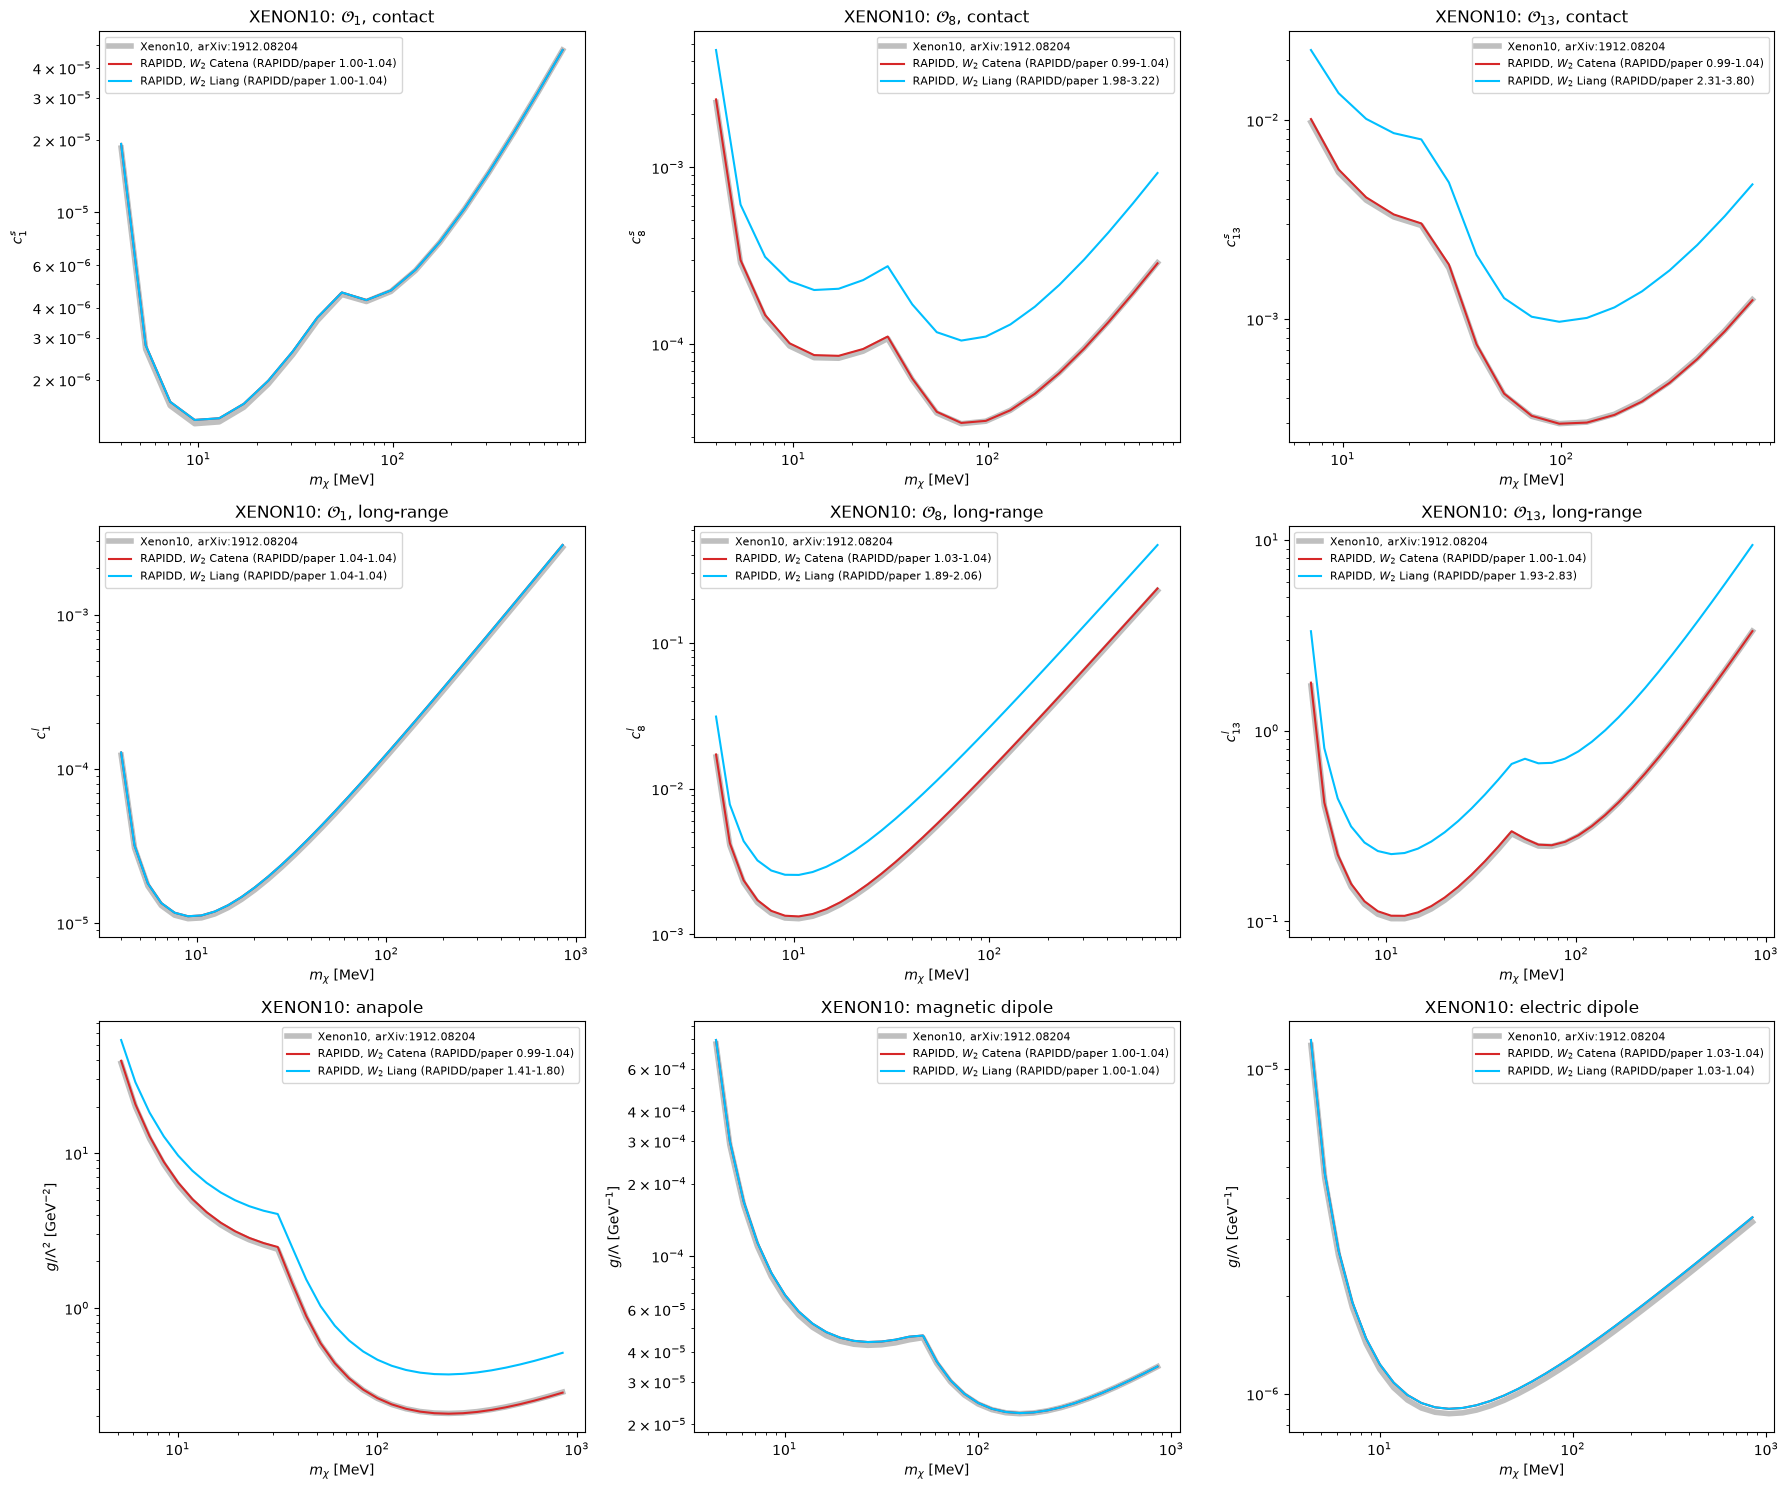

XENON10 c1 contact             W_2 Catena: RAPIDD/paper 1.00-1.04 (median 1.02)
XENON10 c1 contact             W_2 Liang : RAPIDD/paper 1.00-1.04 (median 1.02)
XENON10 c8 contact             W_2 Catena: RAPIDD/paper 0.99-1.04 (median 1.02)
XENON10 c8 contact             W_2 Liang : RAPIDD/paper 1.98-3.22 (median 2.87)
XENON10 c13 contact            W_2 Catena: RAPIDD/paper 0.99-1.04 (median 1.01)
XENON10 c13 contact            W_2 Liang : RAPIDD/paper 2.31-3.80 (median 3.17)
XENON10 c1 long-range          W_2 Catena: RAPIDD/paper 1.04-1.04 (median 1.04)
XENON10 c1 long-range          W_2 Liang : RAPIDD/paper 1.04-1.04 (median 1.04)
XENON10 c8 long-range          W_2 Catena: RAPIDD/paper 1.03-1.04 (median 1.03)
XENON10 c8 long-range          W_2 Liang : RAPIDD/paper 1.89-2.06 (median 2.05)
XENON10 c13 long-range         W_2 Catena: RAPIDD/paper 1.00-1.04 (median 1.02)
XENON10 c13 long-range         W_2 Liang : RAPIDD/paper 1.93-2.83 (median 2.69)
XENON10 anapole                W_2 Caten

In [8]:
w2_styles = {'Catena': dict(color='tab:red'), 'Liang': dict(color='deepskyblue')}
models = {'anapole': r'$g/\Lambda^2$ [GeV$^{-2}$]', 'magnetic_dipole': r'$g/\Lambda$ [GeV$^{-1}$]',
          'electric_dipole': r'$g/\Lambda$ [GeV$^{-1}$]'}
fig_names = {'anapole': 'Anapole', 'magnetic_dipole': 'Magnetic_Dipole', 'electric_dipole': 'Electric_Dipole'}
ratios = {}


def plot_vs_paper(ax, experiment, setter, csv, key):
    """RAPIDD limits with the two signs of W_2 at the masses of the paper curve csv"""
    x_paper, y_paper = np.loadtxt(paper + csv, delimiter=',').T
    m = x_paper / 1e3
    if experiment == 'Xenon1T':
        sel = (m >= 0.02) & (m <= 5.)
        x_paper, y_paper, m = x_paper[sel], y_paper[sel], m[sel]
    ax.plot(x_paper, y_paper, color='k', lw=4, alpha=0.25, label=f'{experiment}, arXiv:1912.08204')
    for convention, style in w2_styles.items():
        rapidd.set_w2_sign(convention)
        lim = rapidd.electron_limits_vs_mass(experiment, m, setter, rhoDM=rhoDM, jchi=jchi, shells=shells)
        r = (lim / y_paper)[np.isfinite(lim)]
        ratios[experiment, key, convention] = r
        ax.plot(x_paper, lim, **style, label=f'RAPIDD, $W_2$ {convention} (RAPIDD/paper {r.min():.2f}-{r.max():.2f})')
    rapidd.set_w2_sign('Liang')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$m_\chi$ [MeV]')
    ax.legend(fontsize=8)


def limits_vs_paper(experiment):
    tag = 'XENON10' if experiment == 'Xenon10' else 'XENON1T'
    fig, axes = plt.subplots(3, 3, figsize=(18, 15))
    for row, (inter, t) in enumerate((('contact', 'C'), ('long-range', 'L'))):
        for ax, op in zip(axes[row], (1, 8, 13)):
            plot_vs_paper(ax, experiment, lambda m, op=op, inter=inter: rapidd.set_any_Ecoeff(1., op, interaction=inter),
                          f'Constraint_Coupling_{t}__{tag}_c{op}.csv', f'c{op} {inter}')
            ax.set_ylabel(f'$c_{{{op}}}^{{{"s" if inter == "contact" else "l"}}}$')
            ax.set_title(f'{tag}: $\\mathcal{{O}}_{{{op}}}$, {inter}')
    for ax, (model, label) in zip(axes[2], models.items()):
        plot_vs_paper(ax, experiment, lambda m, model=model: rapidd.set_any_E_EFT_coeff(model, m, 1.),
                      f'Constraint_{fig_names[model]}__{tag}.csv', model)
        ax.set_ylabel(label)
        ax.set_title(f'{tag}: {model.replace("_", " ")}')
    plt.tight_layout()
    plt.show()
    rapidd.reset_coefficients()
    for (exp, key, convention), r in ratios.items():
        if exp == experiment:
            print(f'{tag} {key:22s} W_2 {convention:6s}: RAPIDD/paper {r.min():.2f}-{r.max():.2f} (median {np.median(r):.2f})')


limits_vs_paper('Xenon10')

## 4. XENON1T limits
### Comparison with Figs. 8 and 10 of arXiv:1912.08204
The paper uses its own XENON1T analysis (4 S2 bins, $g_2 = 33$, the efficiencies of the S2-only paper, an
exposure of 80755 kg day and a Poisson limit without background), RAPIDD the response matrix of the S2-only data
release, its mass dependent ROI and the background subtraction. The same comparisons as for XENON10:

| coupling | $W_2$ Catena | $W_2$ Liang (default) |
|:--|:--|:--|
| $c_1^s$ | 0.52-1.57 (median 0.55) | same |
| $c_8^s$ | 0.50-1.41 (median 0.54) | 1.7-3.4 (median 1.8) |
| $c_{13}^s$ | 0.48-1.34 (median 0.54) | 1.8-3.2 (median 2.0) |
| $c_1^\ell$ | 0.75-2.07 (median 0.85) | same |
| $c_8^\ell$ | 0.57-1.70 (median 0.69) | 1.6-4.2 (median 1.9) |
| $c_{13}^\ell$ | 0.53-1.52 (median 0.56) | 1.6-3.7 (median 1.7) |
| anapole | 0.50-2.93 (median 0.54) | 0.93-5.2 (median 0.98) |
| magnetic dipole | 0.53-3.24 (median 0.56) | same |
| electric dipole | 0.56-3.45 (median 0.68) | same |

With the sign of the paper the RAPIDD XENON1T limits on the couplings are ~1.8 times stronger (~3 on the cross sections) than those of the paper above ~50 MeV, for all the operators: the difference comes from the analysis, not from the rate (which agrees with the paper, section 3). The paper uses an exposure of 80755 kg day (the volume $z \in [-30, -10]$ cm) with the efficiencies of the S2-only paper, 4 S2 bins and no background; RAPIDD the response matrix of the data release (356770 kg day of raw exposure, all the selections included), the optimized ROI and the background subtraction. At the lowest masses of the figures (20-30 MeV) RAPIDD is weaker (up to 1.3-3.5): there the spectrum is close to the threshold of the response, and with the conservative "electron" energy (no binding energy for 5p and 5s) the signal drops (with the total deposited energy $E_e + E_b$ the ratios were 0.42-0.71, median 0.44). The single contributions are not separated here; the RAPIDD XENON1T analysis is validated against the data release below. The sign of $W_2$ changes the limits on $c_8$, $c_{13}$ and the anapole by the same factor as for XENON10.

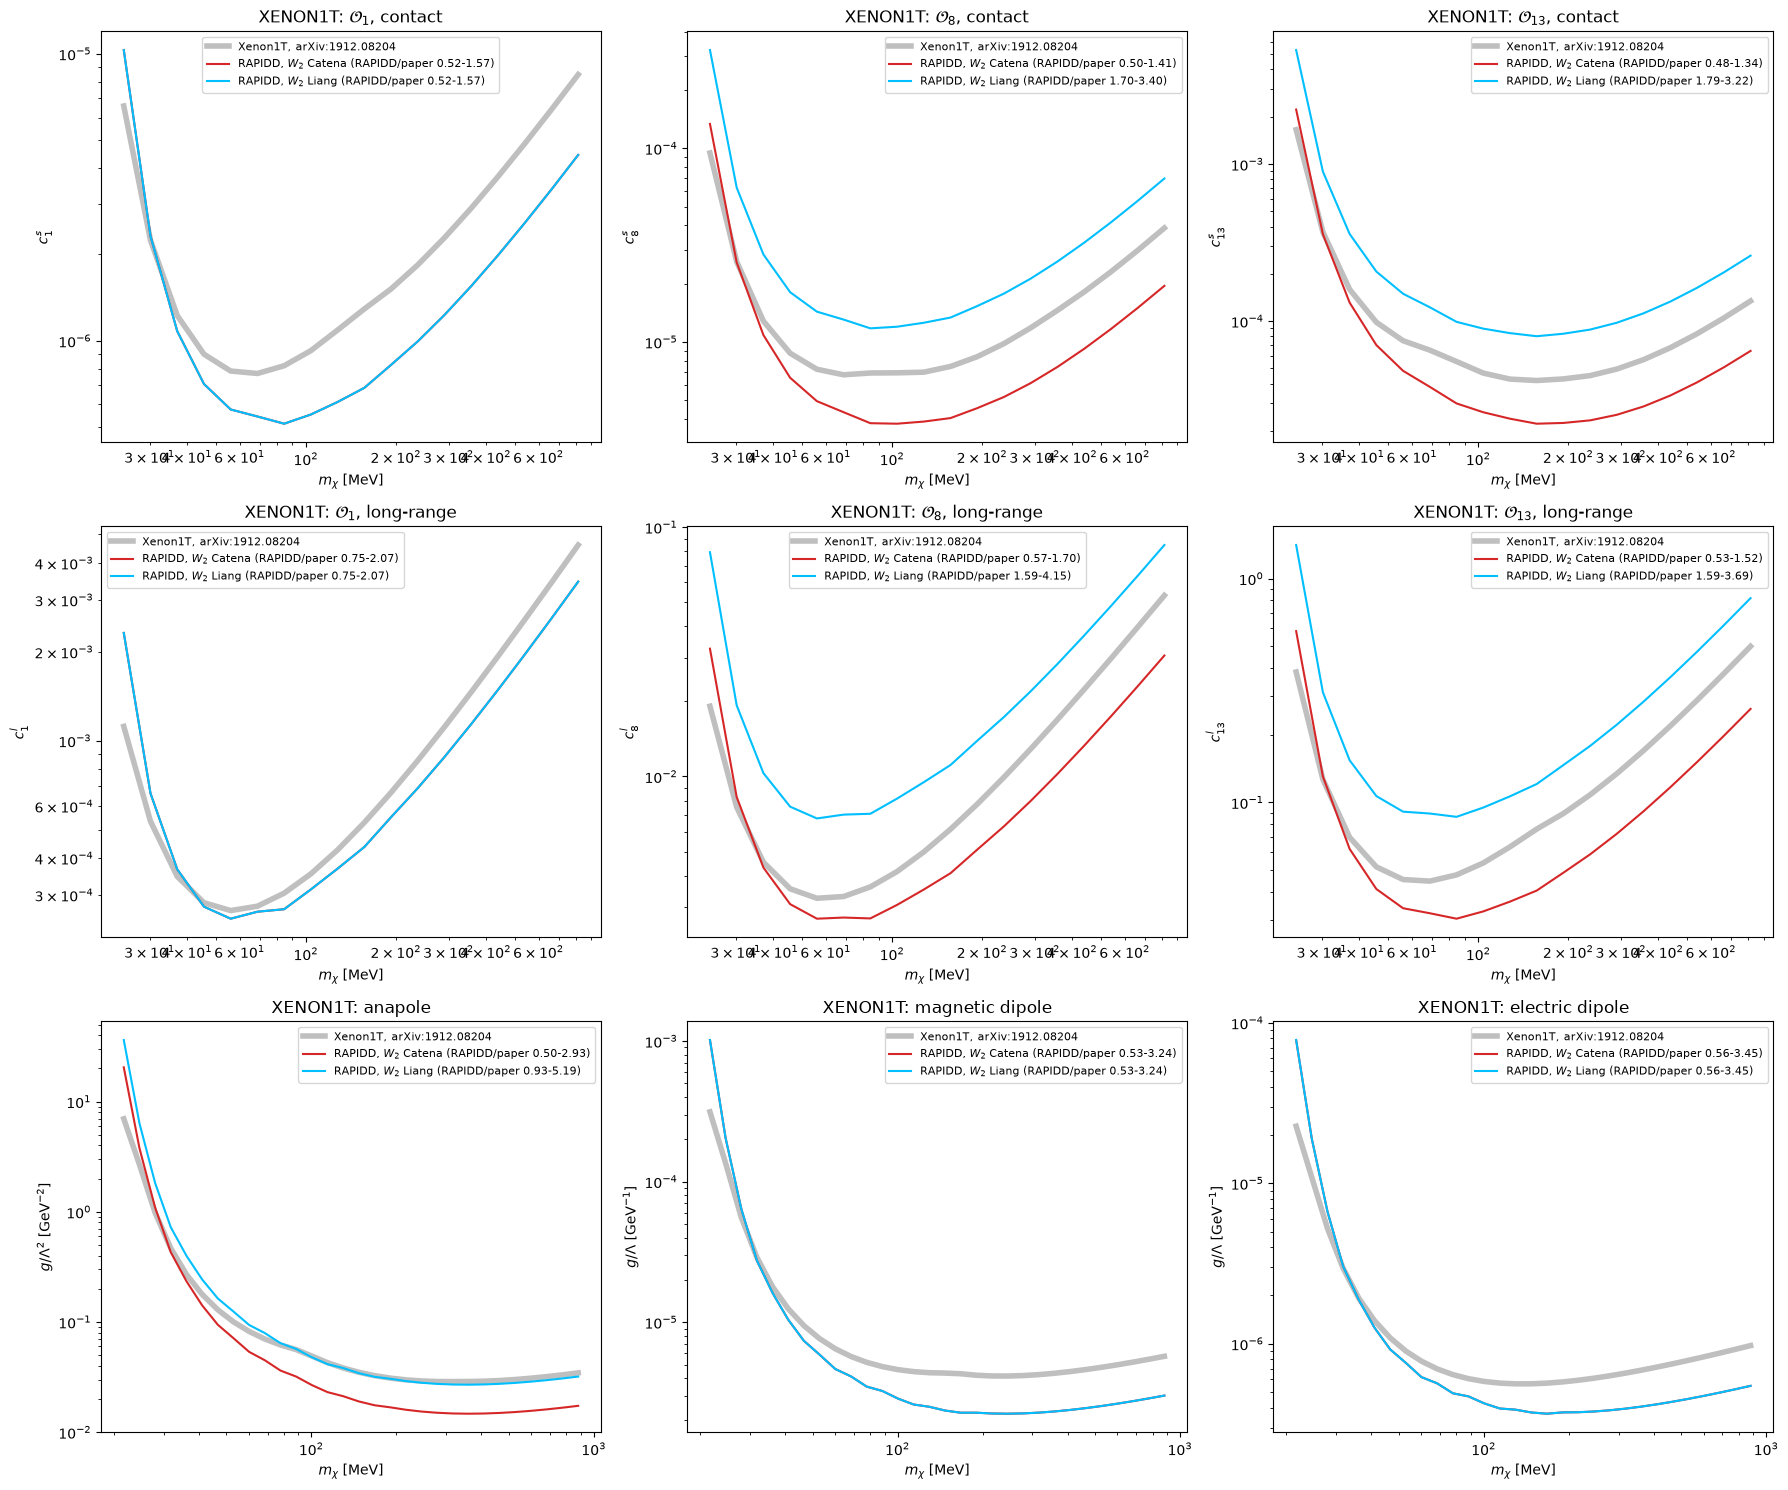

XENON1T c1 contact             W_2 Catena: RAPIDD/paper 0.52-1.57 (median 0.55)
XENON1T c1 contact             W_2 Liang : RAPIDD/paper 0.52-1.57 (median 0.55)
XENON1T c8 contact             W_2 Catena: RAPIDD/paper 0.50-1.41 (median 0.54)
XENON1T c8 contact             W_2 Liang : RAPIDD/paper 1.70-3.40 (median 1.80)
XENON1T c13 contact            W_2 Catena: RAPIDD/paper 0.48-1.34 (median 0.54)
XENON1T c13 contact            W_2 Liang : RAPIDD/paper 1.79-3.22 (median 1.96)
XENON1T c1 long-range          W_2 Catena: RAPIDD/paper 0.75-2.07 (median 0.85)
XENON1T c1 long-range          W_2 Liang : RAPIDD/paper 0.75-2.07 (median 0.85)
XENON1T c8 long-range          W_2 Catena: RAPIDD/paper 0.57-1.70 (median 0.69)
XENON1T c8 long-range          W_2 Liang : RAPIDD/paper 1.59-4.15 (median 1.86)
XENON1T c13 long-range         W_2 Catena: RAPIDD/paper 0.53-1.52 (median 0.56)
XENON1T c13 long-range         W_2 Liang : RAPIDD/paper 1.59-3.69 (median 1.67)
XENON1T anapole                W_2 Caten

In [9]:
limits_vs_paper('Xenon1T')

### Comparison with the XENON1T data release
The S2-only data release ([limits/5d_results_dmelectron.csv](https://github.com/XENON1T/s2only_data_release), copied in `tests/data/xenon1t_s2only`) gives, for the heavy mediator dark photon ($F_\text{DM} = 1$), the excluded $\bar\sigma_e$ (`limit_cm2`) and the expected signal in the ROI at that cross section (`n_expected_signal_mean`, ~25 events above 0.2 GeV). This tests the RAPIDD spectrum and detector response independently of the statistics: below, the RAPIDD signal at the published $\bar\sigma_e$, with the XENON1T halo (SHM, $\rho_\chi = 0.3$ GeV/cm$^3$, $v_0 = 220$, $v_\text{esc} = 544$, $v_E = 232$ km/s: assumed, the standard XENON1T halo, not stated in the S2-only paper) and all the shells.

The response of the data release is a function of the energy of the electronic recoil. The ionized atom releases
the binding energy $E_b$ through de-excitation photons and electrons. XENON1T (arXiv:1907.11485, following
arXiv:1703.00910) and the XENONnT DM-electron limits (arXiv:2601.11296: *"primary electron and shell de-excitation
photon energies with conservative assumptions for de-excitation electrons"*) count the primary electron and the
de-excitation photon of the shell, the one of the secondary quanta of Table II of arXiv:1703.00910 (4d, 4p, 4s:
63.1, 87.9, 50.3 eV; none for 5p, 5s). This is the "electron" convention of RAPIDD (default). The "deposited"
convention, $E_e + E_b$, counts all the binding energy (as the comparison curves of XENONnT with the ionization
factors of Caddell et al.) and gives more signal near threshold.

Results (`tests/test_electron_xenon1t.py`):
- "electron": RAPIDD signal / XENON1T signal = **0.38-0.51** for $50\,\text{MeV} \le m_\chi \le 5\,\text{GeV}$ (0.20 at 30 MeV, 0 at 20 MeV, where the spectrum is below the threshold of the response); the RAPIDD limit on $\bar\sigma_e$ is **1.5-1.9 times** the published one (3.1 at 30 MeV). With the same conversion the wimprates spectra reproduce the XENON1T signal (next section): the factor ~2 is the ratio of the RAPIDD and Essig form factors.
- "deposited": 0.55-0.73 (0.24 at 20 MeV), limit 0.95-1.15 times the published one.
- The limit ratio is smaller than the inverse signal ratio because the statistics differ: RAPIDD needs $N_{90}(n_\text{obs}) - n_\text{bkg} = 18.7$ signal events for $n_\text{obs} = 16$, XENON1T sets the limit with the 10th percentile of the signal and background expectations (nominal minus 1.28 times the systematic uncertainty, arXiv:1907.11485), i.e. at ~25 nominal events.
- Before the energy of the de-excitation was added to $E_e$ the signal ratio was ~0.07-0.14 above 0.2 GeV.

m =  0.02 GeV: XENON1T signal 21.37 | RAPIDD electron  0.01 (ratio 0.00, sigma_e limit x 1445.20) | deposited  5.08 (ratio 0.24, limit x 2.08)
m =  0.03 GeV: XENON1T signal 18.39 | RAPIDD electron  3.73 (ratio 0.20, sigma_e limit x 3.08) | deposited 10.08 (ratio 0.55, limit x 1.14)
m =  0.05 GeV: XENON1T signal 23.96 | RAPIDD electron  9.48 (ratio 0.40, sigma_e limit x 1.75) | deposited 17.51 (ratio 0.73, limit x 0.95)
m =  0.07 GeV: XENON1T signal 22.60 | RAPIDD electron  8.62 (ratio 0.38, sigma_e limit x 1.86) | deposited 15.20 (ratio 0.67, limit x 1.05)
m =  0.10 GeV: XENON1T signal 23.39 | RAPIDD electron  8.86 (ratio 0.38, sigma_e limit x 1.90) | deposited 14.89 (ratio 0.64, limit x 1.13)
m =  0.14 GeV: XENON1T signal 24.05 | RAPIDD electron  9.44 (ratio 0.39, sigma_e limit x 1.86) | deposited 15.30 (ratio 0.64, limit x 1.15)
m =  0.20 GeV: XENON1T signal 25.27 | RAPIDD electron 10.52 (ratio 0.42, sigma_e limit x 1.78) | deposited 16.51 (ratio 0.65, limit x 1.13)
m =  0.30 GeV: XE

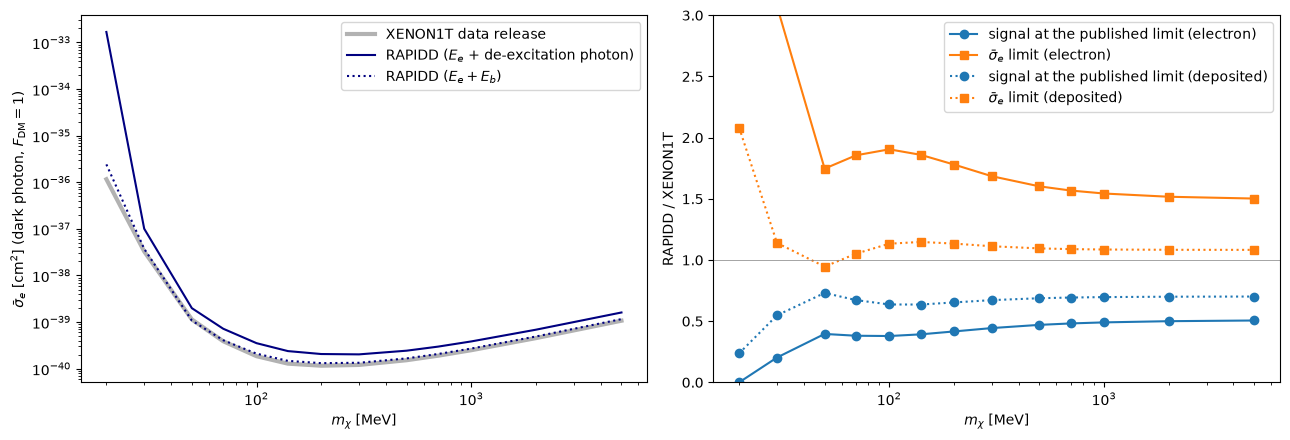

In [10]:
x1t = np.genfromtxt('../tests/data/xenon1t_s2only/5d_results_dmelectron.csv', delimiter=',', names=True)
x1t = x1t[(x1t['mass_gev'] >= 0.02) & (x1t['mass_gev'] <= 5.)]
halo_x1t = os.path.join(tempfile.mkdtemp(), 'halo_table_SHM_XENON1T.dat')
rapidd.calc_halo(halo_x1t, vesc=544., v0=220., ve=232., i=0)
rapidd.read_halo(halo_x1t)
rho_x1t = 0.3

sig_at_lim, sigma_lim = {}, {}
for convention in ('electron', 'deposited'):  # E_e + de-excitation photon (default) or E_e + E_b
    rapidd.set_er_energy_convention(convention)
    sig_at_lim[convention], sigma_lim[convention] = [], []
    for row in x1t:
        m, s = row['mass_gev'], row['limit_cm2']
        rapidd.reset_coefficients()
        rapidd.set_dark_photon_coeff(m, s)
        sig = rapidd.electron_signal('Xenon1T', rhoDM=rho_x1t, mDM=m)
        sig_at_lim[convention].append(sig['signal'])
        sigma_lim[convention].append(s * rapidd.electron_limit(sig, coupling=1.)**2)  # sigma_e ~ c_1^2
    sig_at_lim[convention], sigma_lim[convention] = np.array(sig_at_lim[convention]), np.array(sigma_lim[convention])
rapidd.set_er_energy_convention('electron')
n_x1t = x1t['n_expected_signal_mean']
for i, row in enumerate(x1t):
    print(f"m = {row['mass_gev']:5.2f} GeV: XENON1T signal {n_x1t[i]:5.2f} | RAPIDD electron {sig_at_lim['electron'][i]:5.2f} "
          f"(ratio {sig_at_lim['electron'][i] / n_x1t[i]:.2f}, sigma_e limit x {sigma_lim['electron'][i] / row['limit_cm2']:.2f}) | "
          f"deposited {sig_at_lim['deposited'][i]:5.2f} (ratio {sig_at_lim['deposited'][i] / n_x1t[i]:.2f}, "
          f"limit x {sigma_lim['deposited'][i] / row['limit_cm2']:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(x1t['mass_gev'] * 1e3, x1t['limit_cm2'], 'k', lw=3, alpha=0.3, label='XENON1T data release')
axes[0].plot(x1t['mass_gev'] * 1e3, sigma_lim['electron'], color='navy', label='RAPIDD ($E_e$ + de-excitation photon)')
axes[0].plot(x1t['mass_gev'] * 1e3, sigma_lim['deposited'], color='navy', ls=':', label='RAPIDD ($E_e + E_b$)')
axes[0].set_ylabel(r'$\bar\sigma_e$ [cm$^2$] (dark photon, $F_\mathrm{DM} = 1$)')
for convention, ls in (('electron', '-'), ('deposited', ':')):
    axes[1].plot(x1t['mass_gev'] * 1e3, sig_at_lim[convention] / n_x1t, 'o', ls=ls, color='tab:blue',
                 label=f'signal at the published limit ({convention})')
    axes[1].plot(x1t['mass_gev'] * 1e3, sigma_lim[convention] / x1t['limit_cm2'], 's', ls=ls, color='tab:orange',
                 label=rf'$\bar\sigma_e$ limit ({convention})')
axes[1].axhline(1, color='grey', lw=0.5)
axes[1].set_ylim(0, 3)
axes[1].set_ylabel('RAPIDD / XENON1T')
for ax in axes:
    ax.set_xscale('log')
    ax.set_xlabel(r'$m_\chi$ [MeV]')
    ax.legend()
axes[0].set_yscale('log')
plt.tight_layout()
plt.show()

## 5. XENONnT limits and wimprates
The XENONnT S2-only limit on the dark photon with a heavy mediator ([arXiv:2601.11296](https://arxiv.org/abs/2601.11296),
[data release](https://github.com/XENONnT/s2_only_data_release), `tests/data/xenonnt`; MadDM compares
$\bar\sigma_e$ with it) is computed with [wimprates](https://github.com/JelleAalbers/wimprates) v0.5.0 and the
ionization form factors of Essig et al. (arXiv:1206.2644, arXiv:1703.00910; the ddlDM tables of T.-T. Yu, called
"QEDark" in the data release), with the "electron" energy convention (black curves of Fig. 4(d)). The data
release has no response matrix for electronic recoils, so the limit cannot be recomputed with the RAPIDD spectrum.

Differences between RAPIDD and wimprates (`rate_dme`, default `f_dm='1'`):
- **atomic form factors**: for $\mathcal{O}_1$ the formula is the same as the one of arXiv:1912.08204 with
  $W_1 \leftrightarrow |f_\text{ion}|^2$; RAPIDD uses $W_1$ computed with DarkART (Roothaan-Hartree-Fock bound
  states, hydrogenic continuum with an effective charge), wimprates the tables of Essig et al. (RHF bound states,
  continuum with an effective charge, different normalization and $k'$, $q$ ranges). With the same halo this is the
  only difference of the spectra: RAPIDD / wimprates depends on the shell and on $E_e$ (~0.25-0.7) and is ~0.5
  for the signals;
- **shells**: wimprates has the 5 outer shells, RAPIDD all the 11 (the inner shells contribute less than
  $1.3\times 10^{-3}$ of the XENON1T signal up to 5 GeV);
- **halo**: both use the SHM of arXiv:2105.00599 ($\rho_\chi = 0.3$ GeV/cm$^3$, $v_0 = 238$, $v_\text{esc} = 544$ km/s,
  $\mathbf{v}_\odot = (11.1, 12.2, 7.3)$ km/s), with the Earth speed of March 9 in RAPIDD (253.7 km/s) and of
  February 29 in wimprates (252.1 km/s); below, wimprates uses exactly the RAPIDD $\eta(v_\text{min})$
  (its precomputed `inverse_mean_speed_kms` is replaced by the halo table, `t=None`);
- **detector conversion**: wimprates gives $dR/dE_e$ per shell; the energy convention ("electron" or
  "deposited") and the response are applied here in the same way to the two spectra.

Note: with recent scipy `wimprates.rate_dme` fails because `dme_ionization_ff` returns an array of length 1 to
`scipy.integrate.quad`; it is wrapped to return a scalar.

In [11]:
from scipy.interpolate import interp1d
try:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        import wimprates as wr
        import numericalunits as nu
    have_wr = True
except ImportError:
    have_wr = False
    print('wimprates not installed: skipping the comparison')

wr_shells = ('4s', '4p', '4d', '5s', '5p')
# energy released by the de-excitation of the ion [keV]: binding energy ("deposited") or de-excitation photon
# ("electron", default of RAPIDD: 4d, 4p, 4s; the conservative signal of XENON1T and XENONnT)
E_sec = {'deposited': dict(zip(rapidd.XE_SHELLS, np.array(rapidd.XE_BINDING_ENERGIES) * 1e6)),
         'electron': dict(zip(rapidd.XE_SHELLS, np.array(rapidd.XE_DEEXCITATION_ENERGIES) * 1e6))}

if have_wr:
    _ff = wr.electron.dme_ionization_ff
    wr.electron.dme_ionization_ff = lambda shell, e, q: float(np.squeeze(_ff(shell, e, q)))  # scalar for quad
    wr_unit = 1. / (nu.kg * nu.day * nu.keV)


def use_halo(path):
    """same eta(vmin) in RAPIDD and wimprates"""
    rapidd.read_halo(path)
    if have_wr:
        h = np.loadtxt(path, skiprows=1)  # vmin [km/s], eta [(km/s)^-1]
        wr.electron.inverse_mean_speed_kms = interp1d(h[:, 0], h[:, 1], bounds_error=False, fill_value=0.)


def spectra(m, sigma_e, rho, E_wr=np.geomspace(1e-3, 3., 90)):
    """per-shell dR/dE_e [events/kg/day/keV] of RAPIDD and wimprates (5 outer shells), dark photon F_DM = 1"""
    rapidd.reset_coefficients()
    rapidd.set_dark_photon_coeff(m, sigma_e)
    r = rapidd.difrate_electron(rho, m)
    E = r['E_GeV'][:-1] * 1e6
    out = {}
    for sh in wr_shells:
        y_wr = np.array([wr.rate_dme(e * nu.keV, int(sh[0]), wr.l_to_number[sh[1]], m * nu.GeV / nu.c0**2,
                                     sigma_e * nu.cm**2)
                         for e in E_wr]) / wr_unit * rho / 0.3  # wimprates uses rho = 0.3 GeV/cm^3
        out[sh] = (E, r['rate_shell'][rapidd.XE_SHELLS.index(sh)] * 1e-6, E_wr, y_wr)
    return out


def er_spectrum(spec, which, E_ER, convention='electron'):
    """dR/dE_ER summed over the 5 shells, E_ER = E_e + E_sec (E_sec of the convention)"""
    tot = np.zeros_like(E_ER)
    for sh, (E, y, E_wr, y_wr) in spec.items():
        x, yy = (E, y) if which == 'rapidd' else (E_wr, y_wr)
        tot += np.interp(E_ER, x + E_sec[convention][sh], yy, left=0., right=0.)
    return tot

### Spectra of the single shells
MadDM halo, $\rho_\chi = 0.3$ GeV/cm$^3$.

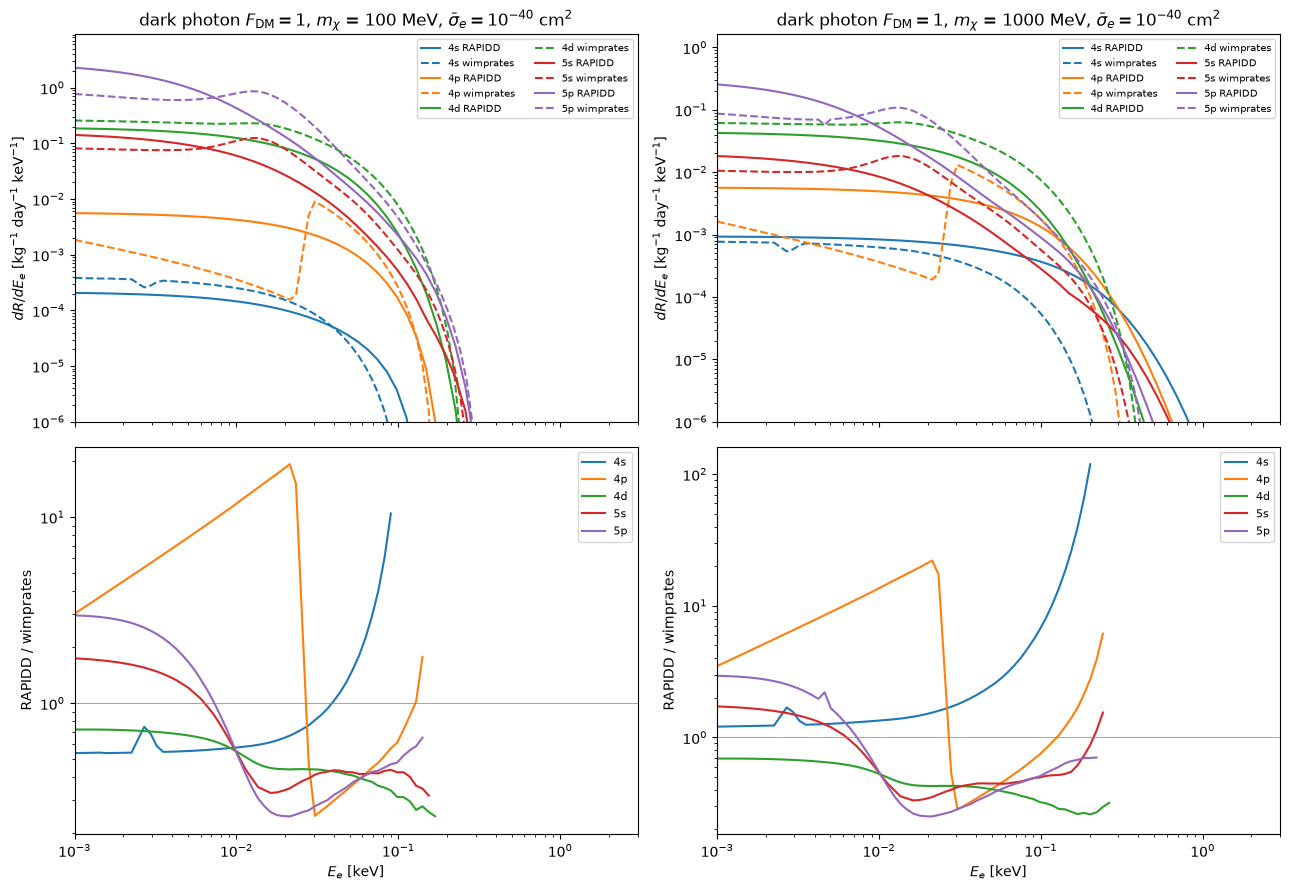

In [12]:
if have_wr:
    use_halo(rapidd.halo_path)
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
    for col, m in enumerate((0.1, 1.0)):
        spec = spectra(m, 1e-40, 0.3)
        for sh, (E, y, E_wr, y_wr) in spec.items():
            l, = axes[0, col].plot(E, y, label=f'{sh} RAPIDD')
            axes[0, col].plot(E_wr, y_wr, ls='--', color=l.get_color(), label=f'{sh} wimprates')
            ok = y_wr > 1e-3 * y_wr.max()
            axes[1, col].plot(E_wr[ok], np.interp(E_wr[ok], E, y) / y_wr[ok], color=l.get_color(), label=sh)
        axes[0, col].set_yscale('log')
        axes[0, col].set_ylim(1e-6, None)
        axes[0, col].set_ylabel(r'$dR/dE_e$ [kg$^{-1}$ day$^{-1}$ keV$^{-1}$]')
        axes[0, col].set_title(rf'dark photon $F_\mathrm{{DM}} = 1$, $m_\chi$ = {m*1e3:g} MeV, $\bar\sigma_e = 10^{{-40}}$ cm$^2$')
        axes[0, col].legend(ncol=2, fontsize=7)
        axes[1, col].axhline(1, color='grey', lw=0.5)
        axes[1, col].set_yscale('log')
        axes[1, col].set_ylabel('RAPIDD / wimprates')
        axes[1, col].set_xlabel('$E_e$ [keV]')
        axes[1, col].set_xscale('log')
        axes[1, col].set_xlim(1e-3, 3)
        axes[1, col].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### XENON1T: the form factors and the data release
The XENON1T signal at the published limits (data release halo of section 4) with the RAPIDD and the wimprates
spectra, both folded with the same response, with the two energy conventions.

In [13]:
if have_wr:
    use_halo(halo_x1t)
    resp = np.loadtxt('../lib/experiments/Xenon1T_S2only/s2_response_er.csv', delimiter=',', skiprows=1)
    E_resp, dE_resp, R_resp = resp[:, 0], resp[:, 2] - resp[:, 1], resp[:, 3:3 + rapidd.S2_BIN_MAX_XENON1T]
    roi_tab = np.loadtxt('../lib/experiments/Xenon1T_S2only/5d_results_dmelectron.dat')

    def roi_signal(spec, m, which, convention):
        dRdS2 = (er_spectrum(spec, which, E_resp, convention) * dE_resp * 356770.) @ R_resp
        lo, hi = (int(round(np.interp(m, roi_tab[:, 0], roi_tab[:, j]))) for j in (1, 2))
        return dRdS2[lo - 1:hi].sum()

    for row in x1t:
        m = row['mass_gev']
        if m not in (0.03, 0.05, 0.1, 0.3, 1.0):
            continue
        spec = spectra(m, row['limit_cm2'], rho_x1t)
        n_x = row['n_expected_signal_mean']
        for convention in ('electron', 'deposited'):
            s_r, s_w = roi_signal(spec, m, 'rapidd', convention), roi_signal(spec, m, 'wimprates', convention)
            print(f'm = {m:4.2f} GeV, {convention:9s}: ROI signal at the published limit RAPIDD {s_r:5.2f}, '
                  f'wimprates {s_w:5.2f}, XENON1T {n_x:5.2f} | RAPIDD/wimprates = {s_r / s_w:.2f}, '
                  f'wimprates/XENON1T = {s_w / n_x:.2f}, RAPIDD/XENON1T = {s_r / n_x:.2f}')


m = 0.03 GeV, electron : ROI signal at the published limit RAPIDD  3.73, wimprates  4.54, XENON1T 18.39 | RAPIDD/wimprates = 0.82, wimprates/XENON1T = 0.25, RAPIDD/XENON1T = 0.20
m = 0.03 GeV, deposited: ROI signal at the published limit RAPIDD 10.08, wimprates 18.15, XENON1T 18.39 | RAPIDD/wimprates = 0.56, wimprates/XENON1T = 0.99, RAPIDD/XENON1T = 0.55
m = 0.05 GeV, electron : ROI signal at the published limit RAPIDD  9.48, wimprates 18.18, XENON1T 23.96 | RAPIDD/wimprates = 0.52, wimprates/XENON1T = 0.76, RAPIDD/XENON1T = 0.40


m = 0.05 GeV, deposited: ROI signal at the published limit RAPIDD 17.51, wimprates 33.34, XENON1T 23.96 | RAPIDD/wimprates = 0.53, wimprates/XENON1T = 1.39, RAPIDD/XENON1T = 0.73


m = 0.10 GeV, electron : ROI signal at the published limit RAPIDD  8.86, wimprates 21.19, XENON1T 23.39 | RAPIDD/wimprates = 0.42, wimprates/XENON1T = 0.91, RAPIDD/XENON1T = 0.38
m = 0.10 GeV, deposited: ROI signal at the published limit RAPIDD 14.89, wimprates 32.64, XENON1T 23.39 | RAPIDD/wimprates = 0.46, wimprates/XENON1T = 1.40, RAPIDD/XENON1T = 0.64


m = 0.30 GeV, electron : ROI signal at the published limit RAPIDD 11.11, wimprates 24.76, XENON1T 25.04 | RAPIDD/wimprates = 0.45, wimprates/XENON1T = 0.99, RAPIDD/XENON1T = 0.44
m = 0.30 GeV, deposited: ROI signal at the published limit RAPIDD 16.83, wimprates 32.80, XENON1T 25.04 | RAPIDD/wimprates = 0.51, wimprates/XENON1T = 1.31, RAPIDD/XENON1T = 0.67
m = 1.00 GeV, electron : ROI signal at the published limit RAPIDD 12.13, wimprates 25.08, XENON1T 24.74 | RAPIDD/wimprates = 0.48, wimprates/XENON1T = 1.01, RAPIDD/XENON1T = 0.49
m = 1.00 GeV, deposited: ROI signal at the published limit RAPIDD 17.24, wimprates 31.67, XENON1T 24.74 | RAPIDD/wimprates = 0.54, wimprates/XENON1T = 1.28, RAPIDD/XENON1T = 0.70


### XENONnT
XENONnT is sensitive to electronic recoils of [0.04, 0.7] keV (arXiv:2601.11296). Without the response matrix,
the ratio of the RAPIDD and wimprates signals is estimated by integrating the two spectra of electronic recoil
energy ("electron" convention, as XENONnT) over this window, with the same halo (the SHM of arXiv:2105.00599 used
by XENONnT and by MadDM). The published limit rescaled by this ratio,
$\bar\sigma_e^\text{RAPIDD} = \bar\sigma_e^\text{XENONnT}\, S_\text{wimprates}/S_\text{RAPIDD}$, approximates the
XENONnT limit computed with the RAPIDD atomic responses. It is written by
[xenonnt_dme_limit_rapidd_ff.py](xenonnt_dme_limit_rapidd_ff.py) in `lib/experiments/XENONnT/XENONnT_DMe_SI_RAPIDD_FF.dat`
(the same ratio is recomputed below). The RAPIDD XENON10 and XENON1T limits with the same halo are shown for reference.

m =  0.04 GeV: RAPIDD / wimprates in [0.04, 0.7] keV: electron 0.575, deposited 0.401 | in [0.1, 0.7] keV: electron 0.519, deposited 0.532


m =  0.05 GeV: RAPIDD / wimprates in [0.04, 0.7] keV: electron 0.557, deposited 0.436 | in [0.1, 0.7] keV: electron 0.466, deposited 0.484


m =  0.07 GeV: RAPIDD / wimprates in [0.04, 0.7] keV: electron 0.518, deposited 0.453 | in [0.1, 0.7] keV: electron 0.426, deposited 0.447


m =  0.10 GeV: RAPIDD / wimprates in [0.04, 0.7] keV: electron 0.493, deposited 0.454 | in [0.1, 0.7] keV: electron 0.411, deposited 0.436


m =  0.20 GeV: RAPIDD / wimprates in [0.04, 0.7] keV: electron 0.487, deposited 0.464 | in [0.1, 0.7] keV: electron 0.433, deposited 0.458


m =  0.50 GeV: RAPIDD / wimprates in [0.04, 0.7] keV: electron 0.504, deposited 0.484 | in [0.1, 0.7] keV: electron 0.472, deposited 0.495


m =  1.00 GeV: RAPIDD / wimprates in [0.04, 0.7] keV: electron 0.512, deposited 0.493 | in [0.1, 0.7] keV: electron 0.488, deposited 0.509


m =  2.00 GeV: RAPIDD / wimprates in [0.04, 0.7] keV: electron 0.517, deposited 0.497 | in [0.1, 0.7] keV: electron 0.496, deposited 0.516


m =  5.00 GeV: RAPIDD / wimprates in [0.04, 0.7] keV: electron 0.519, deposited 0.500 | in [0.1, 0.7] keV: electron 0.500, deposited 0.520


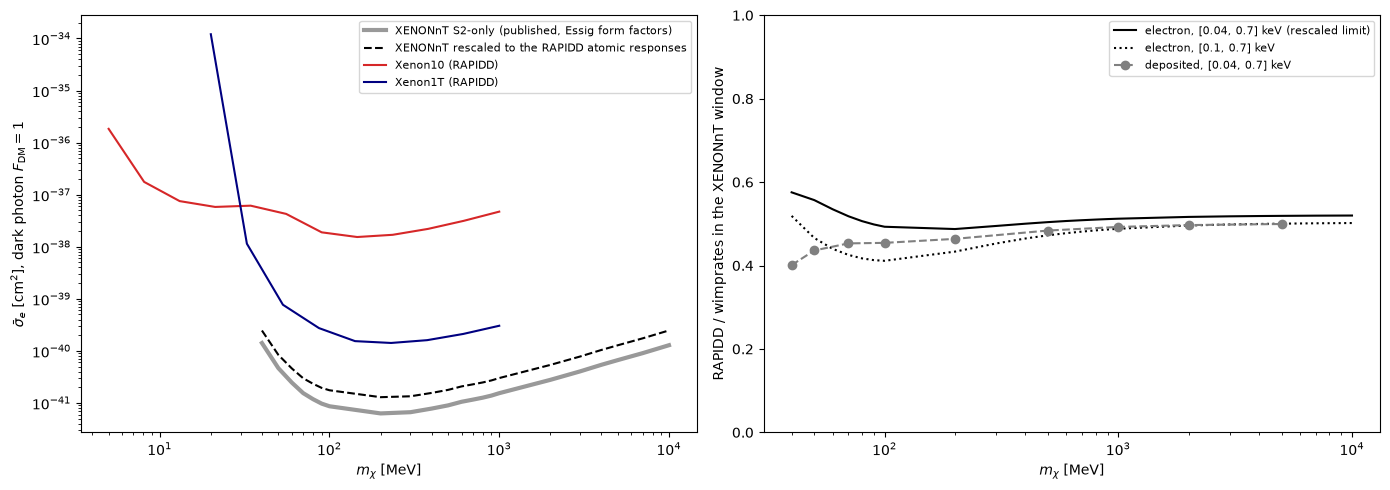

In [14]:
nT = pd.read_csv('../tests/data/xenonnt/XENONnT_SR012_s2_only_wimp_electron_qedark_after_pcl_limit.csv')
# published limit rescaled to the RAPIDD atomic responses (written by xenonnt_dme_limit_rapidd_ff.py)
nT_rapidd = np.loadtxt('../lib/experiments/XENONnT/XENONnT_DMe_SI_RAPIDD_FF.dat')
if have_wr:
    use_halo(rapidd.halo_path)
    m_nt = np.array([0.04, 0.05, 0.07, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0])
    ratio_nt = {}
    for m in m_nt:
        spec = spectra(m, 1e-40, 0.3, E_wr=np.geomspace(1e-3, 1., 80))  # same grids as the script
        for convention in ('electron', 'deposited'):
            for lo in (0.04, 0.1):
                E_ER = np.geomspace(lo, 0.7, 400)
                ratio_nt.setdefault((convention, lo), []).append(
                    np.trapezoid(er_spectrum(spec, 'rapidd', E_ER, convention), E_ER)
                    / np.trapezoid(er_spectrum(spec, 'wimprates', E_ER, convention), E_ER))
        print(f'm = {m:5.2f} GeV: RAPIDD / wimprates in [0.04, 0.7] keV: electron {ratio_nt["electron", 0.04][-1]:.3f}, '
              f'deposited {ratio_nt["deposited", 0.04][-1]:.3f} | in [0.1, 0.7] keV: electron '
              f'{ratio_nt["electron", 0.1][-1]:.3f}, deposited {ratio_nt["deposited", 0.1][-1]:.3f}')
    # the file uses the same ratio (electron, [0.04, 0.7] keV)
    np.testing.assert_allclose(np.interp(m_nt, nT_rapidd[:, 0], nT_rapidd[:, 2]), ratio_nt['electron', 0.04], atol=2e-4, rtol=0)

sigma0 = 1e-40
setter = lambda m: rapidd.set_dark_photon_coeff(m, sigma0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(nT['mass_gev'] * 1e3, nT['limit_cm2'], 'k', lw=3, alpha=0.4, label='XENONnT S2-only (published, Essig form factors)')
ax.plot(nT_rapidd[:, 0] * 1e3, nT_rapidd[:, 1], 'k--', label='XENONnT rescaled to the RAPIDD atomic responses')
for exp, m, color in (('Xenon10', np.geomspace(5e-3, 1., 12), 'tab:red'), ('Xenon1T', np.geomspace(2e-2, 1., 9), 'navy')):
    lim = rapidd.electron_limits_vs_mass(exp, m, setter, rhoDM=0.3)
    ax.plot(m * 1e3, sigma0 * lim**2, color=color, label=f'{exp} (RAPIDD)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$m_\chi$ [MeV]')
ax.set_ylabel(r'$\bar\sigma_e$ [cm$^2$], dark photon $F_\mathrm{DM} = 1$')
ax.legend(fontsize=8)
axes[1].plot(nT_rapidd[:, 0] * 1e3, nT_rapidd[:, 2], 'k-', label='electron, [0.04, 0.7] keV (rescaled limit)')
axes[1].plot(nT_rapidd[:, 0] * 1e3, nT_rapidd[:, 3], 'k:', label='electron, [0.1, 0.7] keV')
if have_wr:
    axes[1].plot(m_nt * 1e3, ratio_nt['deposited', 0.04], 'o--', color='grey', label='deposited, [0.04, 0.7] keV')
axes[1].set_xscale('log')
axes[1].set_ylim(0, 1)
axes[1].set_xlabel(r'$m_\chi$ [MeV]')
axes[1].set_ylabel('RAPIDD / wimprates in the XENONnT window')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

rapidd.reset_coefficients()
rapidd.read_halo(halo_table)  # back to the halo of arXiv:1912.08204


Results:
- the per-shell spectra differ by energy dependent factors (the two form factors have different shapes in $k'$ and $q$); for $E_e \approx$ 10-200 eV RAPIDD / wimprates is ~0.25-0.7 for 5p and 5s and ~0.25-0.55 for 4d;
- XENON1T ROI at the published limits, "electron" convention: wimprates / XENON1T = **0.91-1.01** for 0.1-1 GeV (0.99 at 0.3 GeV, 1.01 at 1 GeV): the wimprates spectra with the conversion of XENONnT reproduce the XENON1T signal, which validates the "electron" convention and the use of the energy response. At 50 and 30 MeV wimprates / XENON1T = 0.76 and 0.25: close to the threshold the conversion of XENON1T (in produced electrons, with their fluctuations) is not reproduced by a shift of the energy. With the "deposited" convention wimprates / XENON1T = 1.28-1.40 above 50 MeV (0.99 at 30 MeV): XENON1T did not count the binding energy. RAPIDD / wimprates = **0.42-0.52** (0.82 at 30 MeV);
- XENONnT window [0.04, 0.7] keV, "electron": **RAPIDD / wimprates = 0.49-0.58** (40 MeV - 10 GeV; 0.40-0.50 with $E_e + E_b$). The XENONnT limit rescaled to the RAPIDD atomic responses is **1.74-2.05 times weaker** than the published one (dashed curve, `XENONnT_DMe_SI_RAPIDD_FF.dat`).

So MadDM, which compares $\bar\sigma_e$ with the published XENONnT limit (`XENONnT_DMe_SI.dat`), implicitly uses the ionization form factors of Essig et al.: with the RAPIDD atomic responses the limit is ~2 times weaker. The rescaled curve is an estimate: the XENONnT efficiency and charge yield inside the window are not released and not included (with [0.1, 0.7] keV the ratio is 0.41-0.50, up to 20% lower at 50-100 MeV). Only the heavy mediator is published by XENONnT; for the light mediator the signal comes almost entirely from $E_\text{ER} < 0.186$ keV, where the charge yield is extrapolated (also for XENON1T).

Before the regeneration of the Xe 4d atomic responses these ratios were 0.32-0.52 (XENON1T ROI) and 0.36-0.40 (XENONnT window, $E_e + E_b$).